<div align="center">

<h2><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h2>


<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<h5><strong> Oleh:</strong></h5>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li>
    <strong>WAHDANIA</strong>
    <div style="margin-top:10px;">
      <strong>H061241070</strong>
    </div>
  </li>
</ul>

<p><strong>DEPARTEMEN GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong></strong></p>
<p><strong></strong></p>
<p><strong>2026</strong></p>

</div>

# **Studi Kasus Geofisika — Eksekusi Prompt R–T–C–I–K–O–Q–V dan Interpretasi**

Notebook ini menjalankan lima studi kasus dari prompt pada notebook sumber: kode Python, keluaran (tabel dan gambar), lalu interpretasi.

| No | Studi kasus | Metode |
|---|---|---|
| 1 | Akuifer dan intrusi air laut | Geolistrik VES (Schlumberger) |
| 2 | Kedalaman batuan dasar untuk fondasi | Seismik refraksi |
| 3 | Sesar dan cekungan | Gravitasi |
| 4 | Batuan ultramafik | Magnetik (IGRF, RTP, sinyal analitik) |
| 5 | Mikrozonasi tapak | Mikrotremor HVSR |

> **Catatan data.** Notebook sumber hanya berisi *prompt* tanpa data lapangan. Data dibuat **sintetis** mengikuti bagian *Input* tiap prompt
> (jumlah titik, spasi, satuan, format kolom). Model sebenarnya diketahui sehingga hasil dapat divalidasi. Seluruh angka adalah ilustrasi metode, bukan temuan lapangan.
> File data dan hasil juga disimpan pada subfolder `kasus_*/data` dan `kasus_*/hasil`.

# **Kasus 1 — Geolistrik VES — Akuifer dan Indikasi Intrusi Air Laut**

## **Data dan metode**
- 10 titik VES Schlumberger tegak lurus pantai, jarak 100–1000 m dari garis pantai (spasi 100 m).
- AB/2 = 1,5–150 m, 16 langkah (log-spasi); MN/2 = 0,5 / 2 / 5 m; arus 20 mA. Kolom CSV: `id_titik, jarak_pantai_m, AB2_m, MN2_m, K, I_mA, dV_mV, rho_semu_ohmm` (`data/data_VES_sintetis.csv`). Noise 3%.
- Model maju: kernel Pekeris/Flathe + integral Hankel (J1). Inversi 1D 3 lapisan (log-parameter, least-squares *trust-region*, 4 tebakan awal berbeda). Nilai ρ semu **tidak dihaluskan**.
- Klasifikasi ρ bersifat **rentang indikatif** (bukan angka pasti): < 5 Ωm = indikasi jenuh air asin; 5–30 = payau (atau lempung, harus dibedakan lewat argumen tambahan); 30–100 = akuifer pasir jenuh air tawar; > 100 = pasir kering/tak jenuh.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.special import j1
from scipy.optimize import least_squares

BASE = os.path.join(os.getcwd(), "kasus_1_ves")
DATA, HASIL = os.path.join(BASE, "data"), os.path.join(BASE, "hasil")
os.makedirs(DATA, exist_ok=True); os.makedirs(HASIL, exist_ok=True)
rng = np.random.default_rng(61241070)

In [6]:
# ------------------------------------------------------------------ forward
def kernel_T(lam, rho, h):
    """Transformasi resistivitas (rekursi Pekeris/Flathe) untuk model berlapis."""
    n = len(rho)
    T = np.full_like(lam, rho[-1])
    for i in range(n - 2, -1, -1):
        th = np.tanh(lam * h[i])
        T = (T + rho[i] * th) / (1.0 + T * th / rho[i])
    return T

def rho_a_schlumberger(ab2, rho, h):
    """rho_a(s) = rho1 + s^2 * Int (T - rho1) J1(lam s) lam dlam, s = AB/2.
    (T - rho1) meluruh ~ exp(-2 lam h1) sehingga integrasi cukup sampai lam ~ 14/h1."""
    ab2 = np.atleast_1d(ab2).astype(float)
    lam_max = 14.0 / h[0]
    lam = np.linspace(1e-6, lam_max, int(lam_max / (0.15 / ab2.max())) + 2000)
    T = kernel_T(lam, np.asarray(rho), np.asarray(h))
    d = (T - rho[0]) * lam
    J = j1(np.outer(ab2, lam))
    return rho[0] + ab2**2 * np.trapz(J * d, lam, axis=1)

In [7]:
# ------------------------------------------------------------------ data sintetis
ab2 = np.round(np.geomspace(1.5, 150, 16), 2)
mn2 = np.where(ab2 < 10, 0.5, np.where(ab2 < 50, 2.0, 5.0))
K = np.pi * (ab2**2 - mn2**2) / (2 * mn2)          # faktor geometri Schlumberger
jarak_pantai = np.arange(100, 1001, 100)            # m dari garis pantai

# Model "sebenarnya" (disembunyikan dari inversi, dipakai hanya untuk validasi)
true_models = []
for x in jarak_pantai:
    r1 = 180 + 0.12 * x                                 # pasir kering
    h1 = 1.8 + 0.0012 * x
    r2 = 10 + 70 * (1 - np.exp(-x / 450))               # akuifer: payau -> tawar
    h2 = 9 + 0.062 * x                                  # tebal akuifer bertambah ke darat
    r3 = 2.5 + 0.0015 * x                               # zona jenuh air asin (baji asin)
    true_models.append(dict(rho=[r1, r2, r3], h=[h1, h2]))

rows, curves = [], {}
for i, (x, m) in enumerate(zip(jarak_pantai, true_models), start=1):
    ra = rho_a_schlumberger(ab2, m["rho"], m["h"])
    ra_noisy = ra * (1 + 0.03 * rng.standard_normal(len(ra)))  # noise 3 %
    curves[i] = ra_noisy
    dV = ra_noisy / K * 20.0                                    # I = 20 mA -> dV (mV)
    for a, mm, k, d_, r_ in zip(ab2, mn2, K, dV, ra_noisy):
        rows.append(dict(id_titik=i, jarak_pantai_m=x, AB2_m=a, MN2_m=mm,
                         K=round(k, 3), I_mA=20.0, dV_mV=round(d_, 4),
                         rho_semu_ohmm=round(r_, 3)))
df = pd.DataFrame(rows)
df.to_csv(os.path.join(DATA, "data_VES_sintetis.csv"), index=False)

In [8]:
# ------------------------------------------------------------------ inversi
def invert(ra_obs, starts=None, fix=None):
    """Inversi 3 lapisan (log-parameter). Kembalikan (rho, h, rms%)."""
    lo = np.log([5, 3, 0.5, 0.8, 2.0]); hi = np.log([800, 300, 30, 12, 120])
    def res(p):
        p_ = np.exp(p)
        r, h = p_[:3], p_[3:]
        return (np.log(rho_a_schlumberger(ab2, r, h)) - np.log(ra_obs))
    best = None
    for s in (starts or [[150, 40, 3, 2.5, 25], [200, 20, 2, 3, 50], [100, 60, 5, 2, 15],
                         [300, 30, 1.5, 4, 40]]):
        sol = least_squares(res, np.log(s), bounds=(lo, hi), method="trf", xtol=1e-10)
        if best is None or sol.cost < best.cost:
            best = sol
    p = np.exp(best.x)
    rms = np.sqrt(np.mean(best.fun**2)) * 100
    return p[:3], p[3:], rms

results = []
for i, x in enumerate(jarak_pantai, start=1):
    r, h, rms = invert(curves[i])
    results.append(dict(titik=i, jarak_pantai_m=x,
                        rho1=r[0], rho2=r[1], rho3=r[2], h1=h[0], h2=h[1],
                        z_atas_L3=h[0] + h[1], RMS_persen=rms))
res = pd.DataFrame(results)

# validasi terhadap model sebenarnya
res["rho2_benar"] = [m["rho"][1] for m in true_models]
res["rho3_benar"] = [m["rho"][2] for m in true_models]
res["z_atas_L3_benar"] = [sum(m["h"]) for m in true_models]
res.round(2).to_csv(os.path.join(HASIL, "hasil_inversi_VES.csv"), index=False)

In [9]:
# ------------------------------------------------------------------ klasifikasi indikatif
def klasifikasi(rho):
    # rentang INDIKATIF (bukan angka pasti), umum dipakai untuk akuifer pasiran pesisir
    if rho < 5:   return "indikasi air asin / jenuh garam"
    if rho < 30:  return "indikasi air payau (atau lempung - perlu pembeda)"
    if rho < 100: return "indikasi akuifer pasir jenuh air tawar"
    return "indikasi pasir kering/ zona tak jenuh"
res["klas_L2"] = res.rho2.apply(klasifikasi)
res["klas_L3"] = res.rho3.apply(klasifikasi)
res[["titik", "jarak_pantai_m", "rho2", "klas_L2", "rho3", "klas_L3", "z_atas_L3"]].round(1)\
    .to_csv(os.path.join(HASIL, "klasifikasi_indikatif.csv"), index=False)

In [10]:
# ------------------------------------------------------------------ uji sensitivitas h2 +-20 %
sens = []
for i in range(len(jarak_pantai)):
    r = res.loc[i, ["rho1", "rho2", "rho3"]].values; h = res.loc[i, ["h1", "h2"]].values
    base = rho_a_schlumberger(ab2, r, h)
    row = {"titik": i + 1}
    for f, nm in [(0.8, "h2_-20%"), (1.2, "h2_+20%")]:
        h_ = h.copy(); h_[1] *= f
        row["misfit_" + nm + "_%"] = np.sqrt(np.mean(np.log(rho_a_schlumberger(ab2, r, h_) / base)**2)) * 100
    # re-inversi dengan h2 ditetapkan -> apakah rho2/rho3 berubah banyak? (ekuivalensi)
    sens.append(row)
sens = pd.DataFrame(sens)

# ekuivalensi: cari pasangan (rho2, h2) yang memberi misfit < noise (3 %) -> rentang h2
eq_rows = []
for i in range(len(jarak_pantai)):
    ra_o = curves[i + 1]
    r0 = res.loc[i, ["rho1", "rho2", "rho3"]].values; h0 = res.loc[i, ["h1", "h2"]].values
    ok_h2, ok_r2 = [], []
    for f in np.linspace(0.7, 1.3, 13):
        def fun(q):  # cari rho2 (dan lainnya) dengan h2 dikunci
            r_ = np.exp(q[:3]); h_ = np.array([np.exp(q[3]), h0[1] * f])
            return np.log(rho_a_schlumberger(ab2, r_, h_)) - np.log(ra_o)
        s = least_squares(fun, np.log([r0[0], r0[1], r0[2], h0[0]]), method="lm")
        rms = np.sqrt(np.mean(s.fun**2)) * 100
        if rms < 4.5:  # sedikit di atas noise 3 %
            ok_h2.append(h0[1] * f); ok_r2.append(np.exp(s.x[1]))
    eq_rows.append(dict(titik=i + 1, h2_min=min(ok_h2), h2_maks=max(ok_h2),
                        rho2_min=min(ok_r2), rho2_maks=max(ok_r2)))
eq = pd.DataFrame(eq_rows)
sens = sens.merge(eq, on="titik")
sens.round(2).to_csv(os.path.join(HASIL, "uji_sensitivitas_ekuivalensi.csv"), index=False)

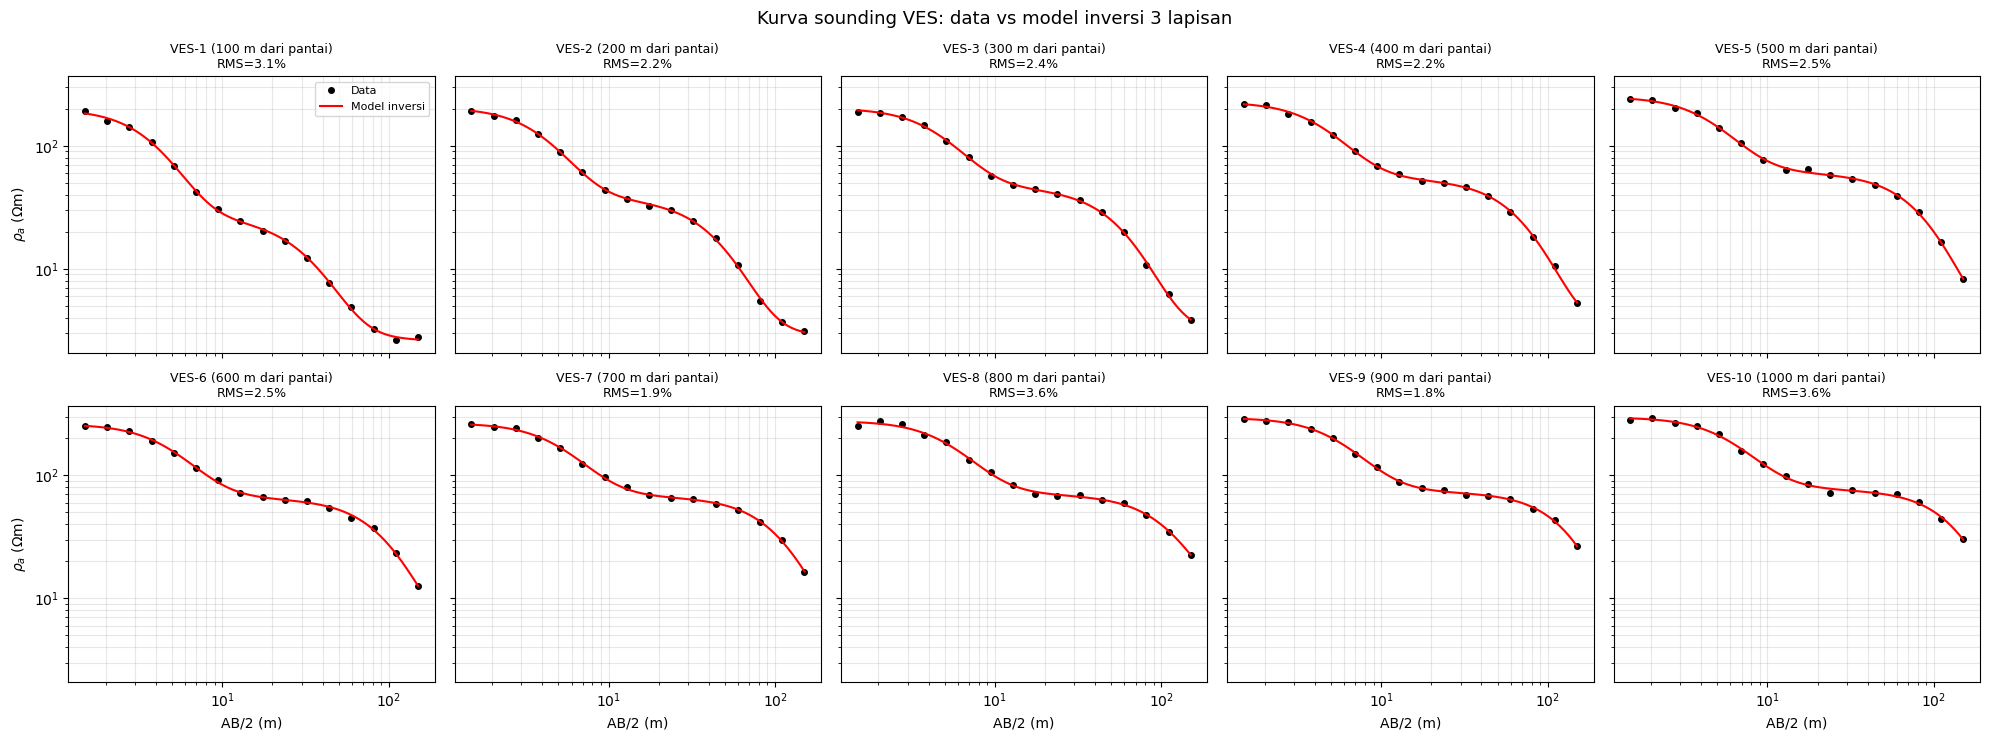

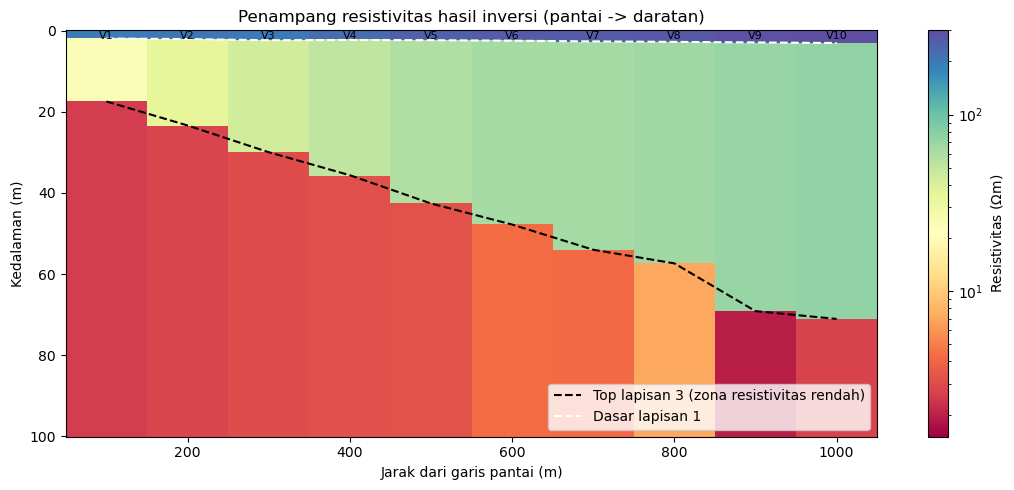

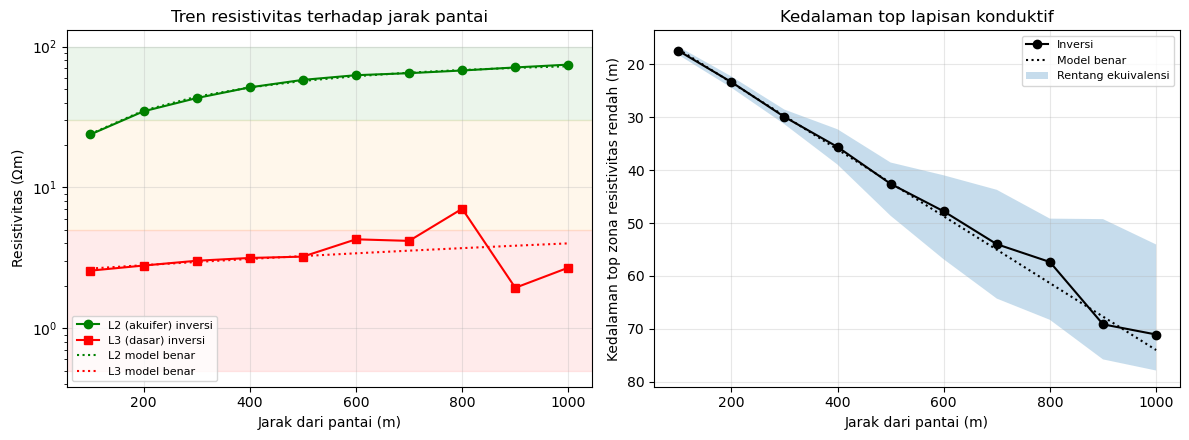

In [11]:
# ------------------------------------------------------------------ gambar
fig, axs = plt.subplots(2, 5, figsize=(20, 7.5), sharex=True, sharey=True)
for i, ax in enumerate(axs.ravel(), start=1):
    ax.loglog(ab2, curves[i], "ko", ms=4, label="Data")
    r = res.loc[i - 1, ["rho1", "rho2", "rho3"]].values; h = res.loc[i - 1, ["h1", "h2"]].values
    f = np.geomspace(1.5, 150, 80)
    ax.loglog(f, rho_a_schlumberger(f, r, h), "r-", label="Model inversi")
    ax.set_title(f"VES-{i} ({jarak_pantai[i-1]} m dari pantai)\nRMS={res.RMS_persen[i-1]:.1f}%", fontsize=9)
    ax.grid(True, which="both", alpha=.3)
    if i == 1: ax.legend(fontsize=8)
for ax in axs[1]: ax.set_xlabel("AB/2 (m)")
for ax in axs[:, 0]: ax.set_ylabel(r"$\rho_a$ ($\Omega$m)")
fig.suptitle("Kurva sounding VES: data vs model inversi 3 lapisan", fontsize=13)
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "01_kurva_sounding.png"), dpi=130); plt.show()

# penampang resistivitas pseudo-2D
zmax = 100
zz = np.linspace(0, zmax, 400)
sect = np.zeros((len(zz), len(jarak_pantai)))
for j in range(len(jarak_pantai)):
    z1 = res.h1[j]; z2 = res.h1[j] + res.h2[j]
    sect[:, j] = np.where(zz < z1, res.rho1[j], np.where(zz < z2, res.rho2[j], res.rho3[j]))
fig, ax = plt.subplots(figsize=(11, 5))
from matplotlib.colors import LogNorm
im = ax.pcolormesh(jarak_pantai, zz, sect, norm=LogNorm(1.5, 300), cmap="Spectral", shading="nearest")
ax.invert_yaxis(); ax.set_xlabel("Jarak dari garis pantai (m)"); ax.set_ylabel("Kedalaman (m)")
ax.plot(jarak_pantai, res.z_atas_L3, "k--", label="Top lapisan 3 (zona resistivitas rendah)")
ax.plot(jarak_pantai, res.h1, "w--", label="Dasar lapisan 1")
for j, x in enumerate(jarak_pantai): ax.text(x, 2, f"V{j+1}", ha="center", fontsize=8)
plt.colorbar(im, label=r"Resistivitas ($\Omega$m)"); ax.legend(loc="lower right")
ax.set_title("Penampang resistivitas hasil inversi (pantai -> daratan)")
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "02_penampang_resistivitas.png"), dpi=130); plt.show()

# tren resistivitas & kedalaman
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
axs[0].semilogy(jarak_pantai, res.rho2, "go-", label="L2 (akuifer) inversi")
axs[0].semilogy(jarak_pantai, res.rho3, "rs-", label="L3 (dasar) inversi")
axs[0].semilogy(jarak_pantai, res.rho2_benar, "g:", label="L2 model benar")
axs[0].semilogy(jarak_pantai, res.rho3_benar, "r:", label="L3 model benar")
axs[0].axhspan(0.5, 5, color="red", alpha=.08); axs[0].axhspan(5, 30, color="orange", alpha=.08)
axs[0].axhspan(30, 100, color="green", alpha=.08)
axs[0].set_xlabel("Jarak dari pantai (m)"); axs[0].set_ylabel(r"Resistivitas ($\Omega$m)")
axs[0].legend(fontsize=8); axs[0].grid(alpha=.3); axs[0].set_title("Tren resistivitas terhadap jarak pantai")
axs[1].plot(jarak_pantai, res.z_atas_L3, "ko-", label="Inversi")
axs[1].plot(jarak_pantai, res.z_atas_L3_benar, "k:", label="Model benar")
axs[1].fill_between(jarak_pantai, res.h1 + eq.h2_min, res.h1 + eq.h2_maks, alpha=.25, label="Rentang ekuivalensi")
axs[1].invert_yaxis(); axs[1].set_xlabel("Jarak dari pantai (m)"); axs[1].set_ylabel("Kedalaman top zona resistivitas rendah (m)")
axs[1].legend(fontsize=8); axs[1].grid(alpha=.3); axs[1].set_title("Kedalaman top lapisan konduktif")
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "03_tren_pantai_daratan.png"), dpi=130); plt.show()

In [12]:
# ------------------------------------------------------------------ ringkasan
print("Rentang rho_semu data: %.1f - %.1f Ohm.m" % (df.rho_semu_ohmm.min(), df.rho_semu_ohmm.max()))
print("\nHasil inversi (dibulatkan):")
print(res[["titik", "jarak_pantai_m", "rho1", "h1", "rho2", "h2", "rho3", "z_atas_L3", "RMS_persen"]].round(1).to_string(index=False))
print("\nValidasi vs model benar:")
print(res[["titik", "rho2", "rho2_benar", "rho3", "rho3_benar", "z_atas_L3", "z_atas_L3_benar"]].round(1).to_string(index=False))
print("\nKlasifikasi indikatif:")
print(res[["titik", "klas_L2", "klas_L3"]].to_string(index=False))
print("\nSensitivitas / ekuivalensi:")
print(sens.round(1).to_string(index=False))

Rentang rho_semu data: 2.6 - 290.1 Ohm.m

Hasil inversi (dibulatkan):
 titik  jarak_pantai_m  rho1  h1  rho2   h2  rho3  z_atas_L3  RMS_persen
     1             100 197.3 1.9  23.8 15.5   2.6       17.4         3.1
     2             200 203.8 2.0  34.7 21.3   2.8       23.3         2.2
     3             300 201.6 2.3  43.1 27.6   3.0       29.9         2.4
     4             400 226.5 2.2  51.3 33.4   3.2       35.6         2.2
     5             500 249.6 2.3  58.0 40.3   3.2       42.6         2.5
     6             600 260.3 2.4  62.6 45.3   4.3       47.8         2.5
     7             700 264.9 2.6  64.7 51.4   4.2       54.0         1.9
     8             800 276.0 2.7  67.6 54.6   7.0       57.4         3.6
     9             900 292.9 2.9  71.0 66.3   1.9       69.1         1.8
    10            1000 295.3 3.0  74.4 68.1   2.7       71.1         3.6

Validasi vs model benar:
 titik  rho2  rho2_benar  rho3  rho3_benar  z_atas_L3  z_atas_L3_benar
     1  23.8        23.9   2.6

## **Interpretasi**
**Karakter kurva.** Semua kurva berbentuk menurun (ρ1 > ρ2 > ρ3, tipe Q): ρ semu mulai ±190–290 Ωm pada AB/2 kecil lalu turun hingga 2–7 Ωm pada AB/2 150 m, tanpa cabang naik di ujung. Artinya tidak ada basement resistif di dalam kedalaman penetrasi; yang ditemui justru lapisan konduktif di bagian dalam. RMS inversi 1,8–3,6% sepadan dengan noise 3%, sehingga model 3 lapisan sudah memadai.

**Lapisan 1 (ρ ≈ 197–295 Ωm, tebal 1,9–3,0 m).** Resistivitas tinggi dengan tebal tipis adalah ciri pasir pantai kering/tak jenuh di atas muka air tanah.

**Lapisan 2 sebagai akuifer.** ρ naik teratur dari 23,8 Ωm (VES-1, 100 m dari pantai) menjadi 74,4 Ωm (VES-10, 1000 m), dengan ketebalan 15,5 m menjadi 68,1 m. Pasir jenuh dengan ρ 30–75 Ωm lazim untuk akuifer air tawar; nilai 23,8 Ωm pada VES-1 jatuh pada rentang payau/peralihan. Jadi indikasinya: akuifer tawar makin baik ke arah daratan, sedangkan dalam ±100–150 m dari pantai sudah berindikasi payau. Naiknya ρ2 ke arah daratan sejalan dengan berkurangnya pengaruh air laut.

**Lapisan 3 dan intrusi air laut.** ρ3 hanya 2,6–4,3 Ωm pada VES-1 sampai VES-7 (konsisten rendah, berurutan naik pelan 2,6 → 4,3 Ωm), jauh di bawah rentang pasir tawar. Top lapisan ini **semakin dalam ke daratan**: 17,4 m (100 m dari pantai) → 29,9 m (300 m) → 47,8 m (600 m) → 71,1 m (1000 m), kemiringan rata-rata ≈ 6 m per 100 m. Pola baji yang menebal ke arah laut di bawah lensa air tawar ini yang menjadi argumen utama **indikasi intrusi air laut**, lebih kuat daripada hanya melihat nilai ρ.

**Membedakan lempung vs air asin.** Tiga argumen: (1) ρ3 < 5 Ωm, di bawah rentang lempung yang umumnya lebih tinggi; (2) top L3 bergerak sistematis mengikuti jarak dari pantai, sedangkan lapisan lempung sedimen cenderung menerus dan lebih konformal; (3) ρ2 di atasnya membaik ke arah daratan. Ketiganya mendukung, tetapi **tidak membuktikan**: tanpa data DHL/log bor, lempung laut yang sangat konduktif tidak dapat dikesampingkan sepenuhnya. Karena itu disebut *indikasi*, dan kualitas air (layak minum atau tidak) tidak disimpulkan.

**Seberapa jauh intrusi.** Indikasi baji asin terlihat di seluruh lintasan (sampai 1000 m), tetapi di VES-8–10 top L3 sudah 57–71 m, mendekati batas kemampuan resolusi (penetrasi efektif ≈ ⅓–½ AB/2 maksimum ≈ 50–75 m). Nilai ρ3 pada VES-8 (7,0 Ωm, tergolong payau) dan VES-9 (1,9 Ωm) menyimpang dari tren halus 2,6–4,3 Ωm; ini lebih tepat dibaca sebagai ketidakpastian resolusi daripada anomali nyata. Validasi memperkuat hal itu: ρ3 sebenarnya 3,7 dan 3,8 Ωm pada kedua titik tersebut.

**Ekuivalensi.** Mengubah h2 ±20% menaikkan misfit menjadi 8–20%, jauh di atas noise 3%, sehingga h2 cukup terkendala. Rentang ekuivalensi sempit di dekat pantai (VES-1: h2 14,7–16,3 m, ≈ ±5%) tetapi melebar di titik dalam (VES-10: 51,0–74,9 m, ≈ −25%/+10%). Jadi kedalaman top L3 di sisi daratan jauh kurang pasti dibanding sisi pantai. ρ2 relatif stabil (VES-10: 72,3–77,0 Ωm).

**Validasi.** ρ2 inversi menyimpang < 3% dari model benar; top L3 meleset ≤ 4 m (terbesar pada VES-8: 57,4 vs 61,4 m).


# **Kasus 2 — Seismik Refraksi — Ketebalan Lapuk dan Kedalaman Batuan Dasar**

## **Data dan metode**
- Lintasan 46 m, 24 geophone spasi 2 m, 5 titik tembak: S1 (x = 0 m), S2 (46 m), S3 tengah (23 m), S4 (−10 m) dan S5 (56 m) sebagai *offset*. Elevasi geophone tersedia. Waktu tempuh dibangkitkan dari model 3 lapisan dengan batas tidak datar + noise 0,4 ms; **1 pick sengaja dihilangkan** (S2–G6) dan **1 pick sengaja salah** (S3–G19, +6 ms), seperti kondisi lapangan. File: `data/first_break_sintetis.csv`.
- QC: pick yang hilang **tidak diisi**; outlier dideteksi dari residual terhadap model robust (ambang 4×MAD, minimum 2 ms).
- Metode wajib 1 — *intercept-time*: segmentasi jarak–waktu tiga garis lurus (pencarian titik patah dengan SSE minimum), kecepatan sebenarnya dari pasangan maju–mundur V = 2/(1/Vf + 1/Vr). Rumus (lapisan datar):
  - h1 = ti2·V1·V2 / (2·√(V2² − V1²))
  - h2 = [ti3 − 2·h1·√(V3² − V1²)/(V1·V3)] · V2·V3 / (2·√(V3² − V2²))
- Metode 2 — inversi *delay-time* seluruh data (116 pick bersih) untuk profil ketebalan sepanjang lintasan: waktu tiba pertama = min(langsung, *head wave* V2, *head wave* V3), 17 simpul interpolasi, regularisasi kehalusan, *loss* robust. Ketidakpastian: 25 realisasi Monte-Carlo noise pick ± variasi regularisasi/kecepatan awal.
- Tidak ada parameter geoteknik (daya dukung) yang dihitung.


In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

BASE = os.path.join(os.getcwd(), "kasus_2_refraksi")
DATA, HASIL = os.path.join(BASE, "data"), os.path.join(BASE, "hasil")
os.makedirs(DATA, exist_ok=True); os.makedirs(HASIL, exist_ok=True)
rng = np.random.default_rng(61241070)

In [14]:
# ------------------------------------------------------------ geometri & model benar
xg = np.arange(0, 47, 2.0)                      # 24 geophone
shots = {"S1": 0.0, "S2": 46.0, "S3": 23.0, "S4": -10.0, "S5": 56.0}
elev = 100 + 1.2 * np.sin(xg / 9) + 0.02 * xg   # elevasi (m) - landai
V1_t, V2_t, V3_t = 380.0, 1350.0, 3400.0

def z1_true(x): return 2.5 + 0.5 * np.cos(2 * np.pi * (np.asarray(x) - 10) / 40)
def z2_true(x):
    x = np.asarray(x)
    return 9.5 + 0.07 * (x - 23) + 3.5 * np.exp(-((x - 34) / 6.0) ** 2)

def coef(V1, V2, V3):
    return (np.sqrt(1 / V1**2 - 1 / V2**2), np.sqrt(1 / V1**2 - 1 / V3**2),
            np.sqrt(1 / V2**2 - 1 / V3**2))

def travel_time(xs, xr, V1, V2, V3, z1f, z2f):
    """first-arrival = min(langsung, head-wave V2, head-wave V3) - pendekatan delay-time."""
    q12, q13, q23 = coef(V1, V2, V3)
    x = np.abs(xr - xs)
    h2s, h2r = z2f(xs) - z1f(xs), z2f(xr) - z1f(xr)
    t1 = x / V1
    t2 = x / V2 + (z1f(xs) + z1f(xr)) * q12
    t3 = x / V3 + (z1f(xs) + z1f(xr)) * q13 + (h2s + h2r) * q23
    return np.minimum(np.minimum(t1, t2), t3), np.argmin([t1, t2, t3], axis=0)

In [15]:
# ------------------------------------------------------------ data pick sintetis (ms)
rows = []
for sname, xs in shots.items():
    t, ph = travel_time(xs, xg, V1_t, V2_t, V3_t, z1_true, z2_true)
    t_ms = np.round(t * 1000 + 0.4 * rng.standard_normal(len(xg)), 1)
    for k, (x, tt) in enumerate(zip(xg, t_ms)):
        rows.append(dict(shot=sname, x_shot=xs, geophone=k + 1, x_geophone=x, elev_m=round(elev[k], 2),
                         offset_m=abs(x - xs), t_ms=tt))
pk = pd.DataFrame(rows)
# kondisi lapangan realistis: 1 pick hilang & 1 pick salah (outlier)
pk.loc[(pk.shot == "S2") & (pk.geophone == 6), "t_ms"] = np.nan      # tidak terbaca (noise)
pk.loc[(pk.shot == "S3") & (pk.geophone == 19), "t_ms"] += 6.0       # salah pick +6 ms
pk.to_csv(os.path.join(DATA, "first_break_sintetis.csv"), index=False)
pk[["geophone", "x_geophone", "elev_m"]].drop_duplicates().to_csv(os.path.join(DATA, "geophone_elevasi.csv"), index=False)

In [16]:
# ------------------------------------------------------------ QC
qc = {}
t_s1_g24 = pk[(pk.shot == "S1") & (pk.geophone == 24)].t_ms.iloc[0]
t_s2_g1 = pk[(pk.shot == "S2") & (pk.geophone == 1)].t_ms.iloc[0]
qc["reciprocal_S1-S2"] = (t_s1_g24, t_s2_g1, abs(t_s1_g24 - t_s2_g1))
qc["n_pick_total"] = len(pk); qc["n_pick_hilang"] = int(pk.t_ms.isna().sum())

def piecewise_fit(off, t, nseg, min_pts=3):
    """Cari titik-patah terbaik (SSE minimum) untuk nseg segmen garis lurus."""
    import itertools
    n = len(off); best = (np.inf, None)
    for cuts in itertools.combinations(range(min_pts, n - min_pts + 1), nseg - 1):
        idx = [0, *cuts, n]
        if any(idx[i + 1] - idx[i] < min_pts for i in range(nseg)): continue
        sse, segs = 0.0, []
        for i in range(nseg):
            sl = slice(idx[i], idx[i + 1])
            p = np.polyfit(off[sl], t[sl], 1)
            sse += np.sum((np.polyval(p, off[sl]) - t[sl]) ** 2); segs.append((p[0], p[1], idx[i], idx[i + 1]))
        if sse < best[0]: best = (sse, segs)
    return best[1]

In [17]:
# ------------------------------------------------------------ inversi delay-time (mesin inversi)
xn = np.linspace(-10, 56, 17)                       # simpul interpolasi (spasi ~4 m)

def make_fun(good_df, lam_s):
    xs_a = good_df.x_shot.values; xr_a = good_df.x_geophone.values; t_a = good_df.t_ms.values / 1000
    def unpack(p):
        return p[:3], p[3:3 + len(xn)], p[3 + len(xn):]
    def fun(p):
        V, z1n, h2n = unpack(p)
        z1f = lambda x: np.interp(x, xn, z1n)
        z2f = lambda x: np.interp(x, xn, z1n + h2n)
        tm, _ = travel_time(xs_a, xr_a, V[0], V[1], V[2], z1f, z2f)
        r = (tm - t_a) / 0.0004
        reg = np.concatenate([np.diff(z1n, 2), np.diff(h2n, 2)]) * lam_s
        return np.concatenate([r, reg])
    return fun, unpack

def run_inversion(good_df, lam_s=1.0, V0=(400, 1300, 3000)):
    fun, unpack = make_fun(good_df, lam_s)
    p0 = np.concatenate([V0, np.full(len(xn), 2.5), np.full(len(xn), 7.0)])
    lo = np.concatenate([[200, 700, 2000], np.full(len(xn), 0.5), np.full(len(xn), 0.5)])
    hi = np.concatenate([[700, 2200, 5000], np.full(len(xn), 8.0), np.full(len(xn), 25.0)])
    sol = least_squares(fun, p0, bounds=(lo, hi), loss="soft_l1", f_scale=1.5, max_nfev=300)
    return sol, unpack

In [18]:
# ------------------------------------------------------------ QC outlier berbasis residual model
valid = pk[pk.t_ms.notna() & (pk.offset_m > 0)].copy()
sol0, unpack0 = run_inversion(valid)
V0_, z10, h20 = unpack0(sol0.x)
tm0, _ = travel_time(valid.x_shot.values, valid.x_geophone.values, *V0_,
                     lambda x: np.interp(x, xn, z10), lambda x: np.interp(x, xn, z10 + h20))
res0 = valid.t_ms.values - tm0 * 1000
mad = np.median(np.abs(res0 - np.median(res0))) * 1.4826
bad = np.abs(res0) > max(4 * mad, 2.0)
flag = [(r.shot, int(r.geophone), float(r.offset_m), round(float(e), 1)) for r, e in zip(valid[bad].itertuples(), res0[bad])]
pk["flag_outlier"] = False
for (sname, g, o, e) in flag:
    pk.loc[(pk.shot == sname) & (pk.geophone == g), "flag_outlier"] = True
pk.to_csv(os.path.join(HASIL, "first_break_setelah_QC.csv"), index=False)
print("MAD residual awal = %.2f ms ; outlier terdeteksi: %s" % (mad, flag))

MAD residual awal = 0.33 ms ; outlier terdeteksi: [('S3', 19, 13.0, 5.0)]


In [19]:
# ------------------------------------------------------------ segmentasi per cabang (pick bersih)
branches = {}
for sname, xs in shots.items():
    dd = pk[(pk.shot == sname) & pk.t_ms.notna() & (~pk.flag_outlier)]
    for side, sel in [("kanan", dd.x_geophone > xs), ("kiri", dd.x_geophone < xs)]:
        bb = dd[sel].sort_values("offset_m")
        if len(bb) >= 9: branches[(sname, side)] = (bb.offset_m.values, bb.t_ms.values / 1000)

fits = {}
for key, (off, t) in branches.items():
    nseg = 3 if key[0] in ("S1", "S2") else 2
    fits[key] = (nseg, piecewise_fit(off, t, nseg))

In [20]:
# ------------------------------------------------------------ intercept-time
vel_tab = []
for key, (nseg, segs) in fits.items():
    for i, (a, b, i0, i1) in enumerate(segs):
        off = branches[key][0]
        vel_tab.append(dict(shot=key[0], cabang=key[1], segmen=i + 1, v_semu_ms=1 / a, intercept_ms=b * 1000,
                            offset_awal_m=off[i0], offset_akhir_m=off[i1 - 1], n_pick=i1 - i0))
vel = pd.DataFrame(vel_tab); vel.round(1).to_csv(os.path.join(HASIL, "segmen_jarak_waktu.csv"), index=False)

# Kecepatan dari intercept-time (pasangan maju-mundur, V = 2/(1/Vf + 1/Vr))
V1 = vel[(vel.segmen == 1) & (vel.shot.isin(["S1", "S2"]))].v_semu_ms.mean()
def seg_v(shot, cab, seg): return vel[(vel.shot == shot) & (vel.cabang == cab) & (vel.segmen == seg)].v_semu_ms.iloc[0]
def seg_ti(shot, cab, seg): return vel[(vel.shot == shot) & (vel.cabang == cab) & (vel.segmen == seg)].intercept_ms.iloc[0] / 1000
v2f, v2r = seg_v("S1", "kanan", 2), seg_v("S2", "kiri", 2)
v3f, v3r = seg_v("S1", "kanan", 3), seg_v("S2", "kiri", 3)
V2 = 2 / (1 / v2f + 1 / v2r); V3 = 2 / (1 / v3f + 1 / v3r)
v3f_o, v3r_o = seg_v("S4", "kanan", 2), seg_v("S5", "kiri", 2)
V3_offset = 2 / (1 / v3f_o + 1 / v3r_o)
print(f"Intercept-time: V1={V1:.0f}  V2 (maju {v2f:.0f}/mundur {v2r:.0f}) = {V2:.0f}  "
      f"V3 (maju {v3f:.0f}/mundur {v3r:.0f}) = {V3:.0f} | cek V3 dari S4/S5 offset = {V3_offset:.0f}")

def intercept_depths(ti2, ti3, V1, V2, V3):
    """Rumus intercept-time (lapisan datar):
       h1 = ti2*V1*V2 / (2*sqrt(V2^2 - V1^2))
       h2 = (ti3 - 2*h1*sqrt(V3^2 - V1^2)/(V1*V3)) * V2*V3 / (2*sqrt(V3^2 - V2^2))"""
    h1 = ti2 * V1 * V2 / (2 * np.sqrt(V2**2 - V1**2))
    h2 = (ti3 - 2 * h1 * np.sqrt(V3**2 - V1**2) / (V1 * V3)) * V2 * V3 / (2 * np.sqrt(V3**2 - V2**2))
    return h1, h2

ic = []
for sh, cab, lab, xx in [("S1", "kanan", "bawah shot S1 (x=0 m)", 0), ("S2", "kiri", "bawah shot S2 (x=46 m)", 46)]:
    h1, h2 = intercept_depths(seg_ti(sh, cab, 2), seg_ti(sh, cab, 3), V1, V2, V3)
    ic.append(dict(lokasi=lab, ti2_ms=seg_ti(sh, cab, 2) * 1000, ti3_ms=seg_ti(sh, cab, 3) * 1000,
                   h1_m=h1, h2_m=h2, kedalaman_bedrock_m=h1 + h2,
                   bedrock_benar_m=float(z2_true(xx))))
ic = pd.DataFrame(ic); ic.round(2).to_csv(os.path.join(HASIL, "intercept_time.csv"), index=False)

Intercept-time: V1=392  V2 (maju 1258/mundur 1281) = 1270  V3 (maju 2535/mundur 3643) = 2990 | cek V3 dari S4/S5 offset = 3002


In [21]:
# ------------------------------------------------------------ inversi akhir (pick bersih) + ketidakpastian
good = pk[pk.t_ms.notna() & (~pk.flag_outlier) & (pk.offset_m > 0)].copy()
sol, unpack = run_inversion(good, lam_s=1.0)
Vm, z1n, h2n = unpack(sol.x)
z1_inv = np.interp(xg, xn, z1n); z2_inv = np.interp(xg, xn, z1n + h2n)
tm, _ = travel_time(good.x_shot.values, good.x_geophone.values, *Vm,
                    lambda x: np.interp(x, xn, z1n), lambda x: np.interp(x, xn, z1n + h2n))
rms_ms = np.sqrt(np.mean((tm * 1000 - good.t_ms.values) ** 2))
print(f"Inversi akhir: V1={Vm[0]:.0f} V2={Vm[1]:.0f} V3={Vm[2]:.0f}  RMS={rms_ms:.2f} ms  (n={len(good)})")

# (a) acak: Monte-Carlo noise picking
n_mc = 25; Z1, Z2, VV = [], [], []
base_t = good.t_ms.values.copy()
for _ in range(n_mc):
    g2 = good.copy(); g2["t_ms"] = base_t + 0.4 * rng.standard_normal(len(g2))
    s2, up = run_inversion(g2, lam_s=1.0)
    V_, a_, b_ = up(s2.x)
    VV.append(V_); Z1.append(np.interp(xg, xn, a_)); Z2.append(np.interp(xg, xn, a_ + b_))
Z1, Z2, VV = np.array(Z1), np.array(Z2), np.array(VV)
z2_lo_mc, z2_hi_mc = np.percentile(Z2, [2.5, 97.5], axis=0)
z1_lo, z1_hi = np.percentile(Z1, [2.5, 97.5], axis=0)
# (b) sistematik: variasi regularisasi (kehalusan) & kecepatan awal
var = []
for lam_s in (0.3, 1.0, 3.0):
    s3, up = run_inversion(good, lam_s=lam_s, V0=(450, 1200, 2800))
    V_, a_, b_ = up(s3.x); var.append(np.interp(xg, xn, a_ + b_))
var = np.array(var)
z2_lo = np.minimum(z2_lo_mc, var.min(0)); z2_hi = np.maximum(z2_hi_mc, var.max(0))

prof = pd.DataFrame(dict(x_m=xg, elevasi_m=elev.round(2),
                         tebal_lapuk_z1_m=z1_inv, z1_lo=z1_lo, z1_hi=z1_hi,
                         kedalaman_bedrock_z2_m=z2_inv, z2_lo=z2_lo, z2_hi=z2_hi,
                         z1_benar=z1_true(xg), z2_benar=z2_true(xg)))
prof["elev_bedrock_m"] = prof.elevasi_m - prof.kedalaman_bedrock_z2_m
prof.round(2).to_csv(os.path.join(HASIL, "profil_kedalaman_bedrock.csv"), index=False)
vsum = pd.DataFrame(dict(lapisan=["V1 (lapuk)", "V2 (menengah)", "V3 (bedrock)"], inversi=Vm,
                         mc_std=VV.std(0), intercept_time=[V1, V2, V3], benar=[V1_t, V2_t, V3_t]))
vsum.round(1).to_csv(os.path.join(HASIL, "kecepatan_lapisan.csv"), index=False)

Inversi akhir: V1=378 V2=1345 V3=3341  RMS=0.34 ms  (n=116)


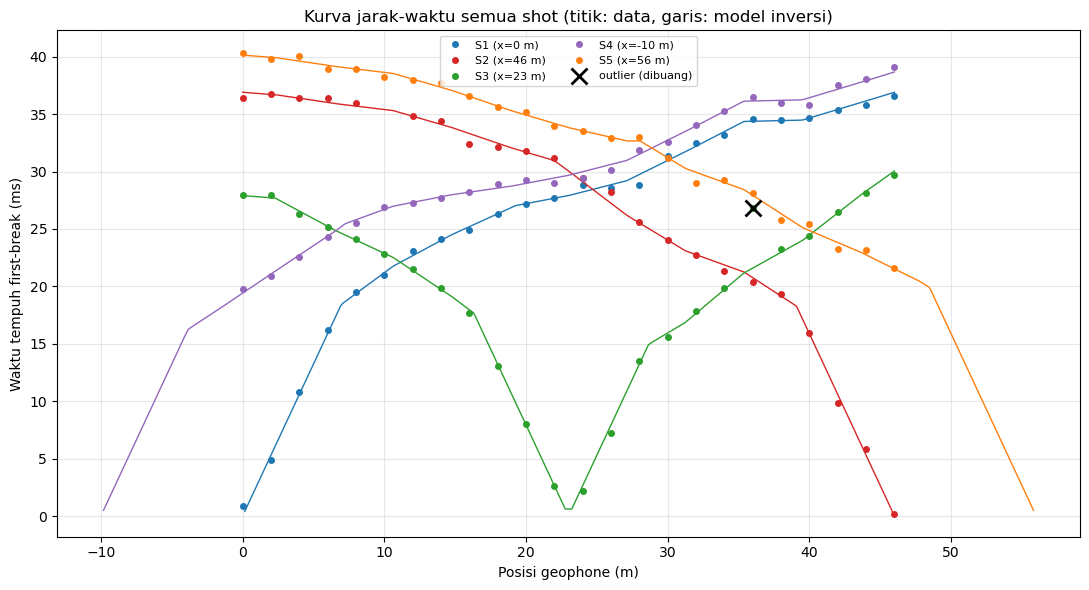

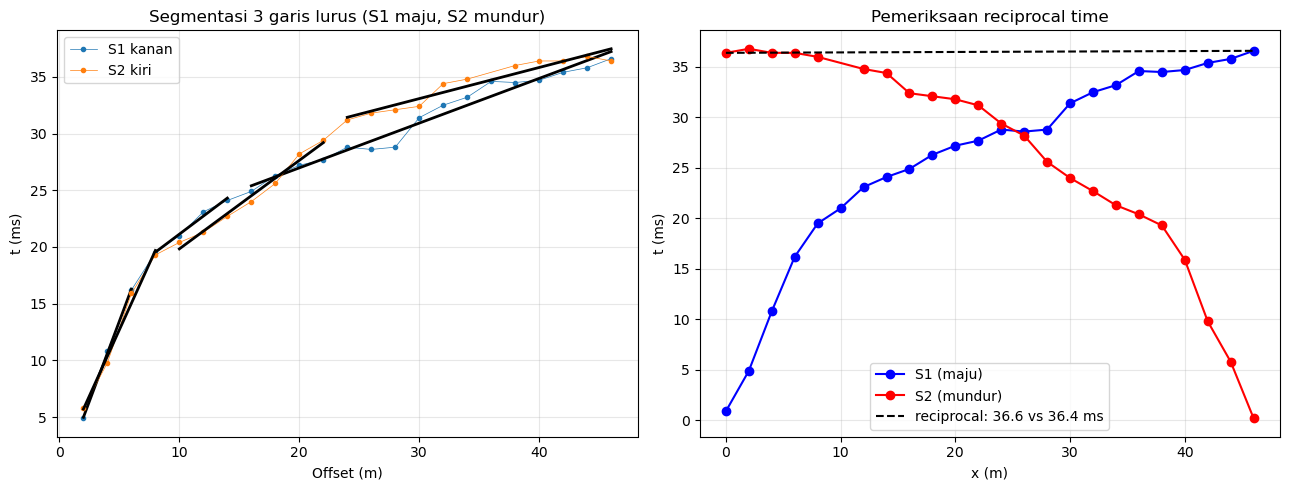

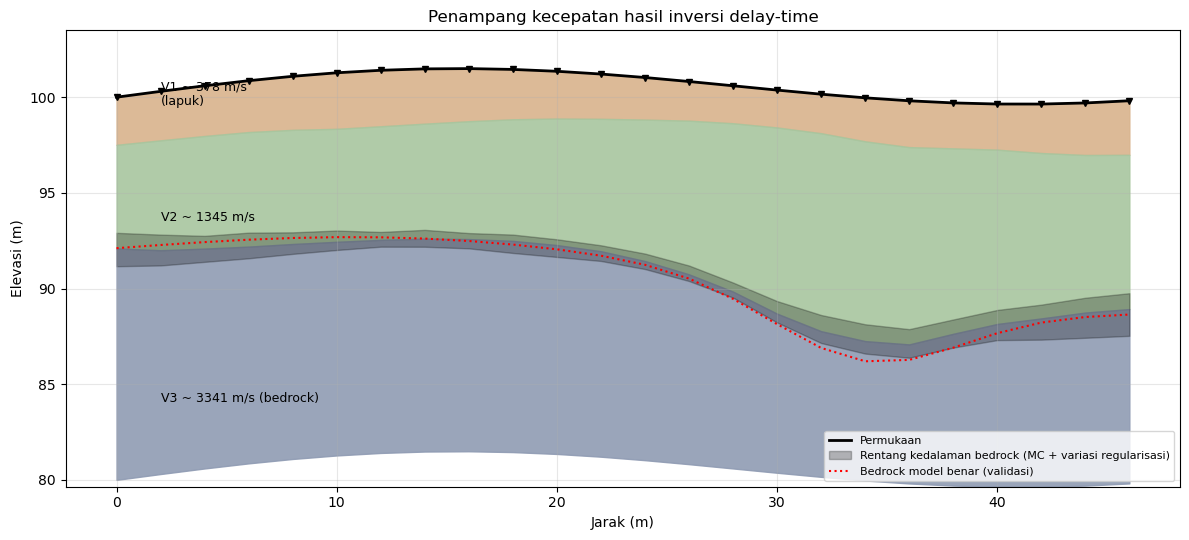

In [22]:
# ------------------------------------------------------------ gambar
cols = dict(S1="tab:blue", S2="tab:red", S3="tab:green", S4="tab:purple", S5="tab:orange")
fig, ax = plt.subplots(figsize=(11, 6))
for s, xs in shots.items():
    d = pk[(pk.shot == s) & pk.t_ms.notna()]
    ax.plot(d.x_geophone, d.t_ms, "o", color=cols[s], ms=4, label=f"{s} (x={xs:g} m)")
    xx = np.linspace(min(xs, 0), max(xs, 46), 300)
    xx = xx[np.abs(xx - xs) > 0.1]
    tt, _ = travel_time(xs, xx, *Vm, lambda x: np.interp(x, xn, z1n), lambda x: np.interp(x, xn, z1n + h2n))
    ax.plot(xx, tt * 1000, "-", color=cols[s], lw=1)
o = pk[pk.flag_outlier]
ax.plot(o.x_geophone, o.t_ms, "kx", ms=12, mew=2, label="outlier (dibuang)")
ax.set_xlabel("Posisi geophone (m)"); ax.set_ylabel("Waktu tempuh first-break (ms)")
ax.set_title("Kurva jarak-waktu semua shot (titik: data, garis: model inversi)")
ax.grid(alpha=.3); ax.legend(fontsize=8, ncol=2); fig.tight_layout()
fig.savefig(os.path.join(HASIL, "01_kurva_jarak_waktu.png"), dpi=130); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for (s, side), (off, t) in branches.items():
    if s not in ("S1", "S2"): continue
    axs[0].plot(off, t * 1000, "o-", ms=3, lw=.5, label=f"{s} {side}")
    nseg, segs = fits[(s, side)]
    for (a, b, i0, i1) in segs:
        axs[0].plot(off[i0:i1], (a * off[i0:i1] + b) * 1000, "k-", lw=2)
axs[0].set_xlabel("Offset (m)"); axs[0].set_ylabel("t (ms)"); axs[0].legend(); axs[0].grid(alpha=.3)
axs[0].set_title("Segmentasi 3 garis lurus (S1 maju, S2 mundur)")
d1 = pk[(pk.shot == "S1") & pk.t_ms.notna()].sort_values("x_geophone")
d2 = pk[(pk.shot == "S2") & pk.t_ms.notna()].sort_values("x_geophone")
axs[1].plot(d1.x_geophone, d1.t_ms, "bo-", label="S1 (maju)"); axs[1].plot(d2.x_geophone, d2.t_ms, "ro-", label="S2 (mundur)")
axs[1].plot([0, 46], [t_s2_g1, t_s1_g24], "k--", label=f"reciprocal: {t_s1_g24} vs {t_s2_g1} ms")
axs[1].set_xlabel("x (m)"); axs[1].set_ylabel("t (ms)"); axs[1].legend(); axs[1].grid(alpha=.3)
axs[1].set_title("Pemeriksaan reciprocal time")
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "02_segmentasi_dan_reciprocal.png"), dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(12, 5.5))
E = elev
ax.plot(xg, E, "k-", lw=2, label="Permukaan")
ax.fill_between(xg, E, E - prof.tebal_lapuk_z1_m, color="#d9b38c", alpha=.9)
ax.fill_between(xg, E - prof.tebal_lapuk_z1_m, E - prof.kedalaman_bedrock_z2_m, color="#a8c69f", alpha=.9)
ax.fill_between(xg, E - prof.kedalaman_bedrock_z2_m, E - 20, color="#8f9bb3", alpha=.9)
ax.fill_between(xg, E - z2_hi, E - z2_lo, color="k", alpha=.25, label="Rentang kedalaman bedrock (MC + variasi regularisasi)")
ax.plot(xg, E - z2_true(xg), "r:", lw=1.5, label="Bedrock model benar (validasi)")
ax.plot(xg, E, "kv", ms=5)
ax.text(2, E.mean() - 1.0, f"V1 ~ {Vm[0]:.0f} m/s\n(lapuk)", fontsize=9)
ax.text(2, E.mean() - 7, f"V2 ~ {Vm[1]:.0f} m/s", fontsize=9)
ax.text(2, E.mean() - 16.5, f"V3 ~ {Vm[2]:.0f} m/s (bedrock)", fontsize=9)
ax.set_xlabel("Jarak (m)"); ax.set_ylabel("Elevasi (m)"); ax.set_ylim(E.min() - 20, E.max() + 2)
ax.set_title("Penampang kecepatan hasil inversi delay-time"); ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=.3); fig.tight_layout(); fig.savefig(os.path.join(HASIL, "03_penampang_kecepatan.png"), dpi=130); plt.show()

In [23]:
# ------------------------------------------------------------ ringkasan
print("\nQC:", qc); print("Outlier terdeteksi:", flag)
print("\nSegmen jarak-waktu:\n", vel.round(1).to_string(index=False))
print("\nIntercept-time:\n", ic.round(2).to_string(index=False))
print("\nKecepatan:\n", vsum.round(1).to_string(index=False))
print("\nProfil kedalaman:\n", prof.round(1).to_string(index=False))
print("\nBedrock depth: min %.1f - maks %.1f m (rata2 %.1f) | z1: %.1f - %.1f m" %
      (prof.kedalaman_bedrock_z2_m.min(), prof.kedalaman_bedrock_z2_m.max(), prof.kedalaman_bedrock_z2_m.mean(),
       prof.tebal_lapuk_z1_m.min(), prof.tebal_lapuk_z1_m.max()))
print("Lebar rentang bedrock: rata2 %.1f m, maks %.1f m" % ((z2_hi - z2_lo).mean(), (z2_hi - z2_lo).max()))
print("RMS galat vs benar z2: %.2f m" % np.sqrt(np.mean((z2_inv - z2_true(xg)) ** 2)))


QC: {'reciprocal_S1-S2': (36.6, 36.4, 0.20000000000000284), 'n_pick_total': 120, 'n_pick_hilang': 1}
Outlier terdeteksi: [('S3', 19, 13.0, 5.0)]

Segmen jarak-waktu:
 shot cabang  segmen  v_semu_ms  intercept_ms  offset_awal_m  offset_akhir_m  n_pick
  S1  kanan       1      354.0          -0.7            2.0             6.0       3
  S1  kanan       2     1257.9          13.2            8.0            14.0       4
  S1  kanan       3     2535.4          19.1           16.0            46.0      16
  S2   kiri       1      429.2           1.1            2.0             8.0       4
  S2   kiri       2     1281.5          12.0           10.0            22.0       7
  S2   kiri       3     3642.7          24.8           24.0            46.0      11
  S3  kanan       1      354.0          -0.8            1.0             5.0       3
  S3  kanan       2     1161.0          10.0            7.0            23.0       8
  S3   kiri       1      396.8           0.3            1.0             7.0 

## **Interpretasi**
**Kualitas data.** Pick konsisten: reciprocal time cocok dalam 0,2 ms, dan satu-satunya outlier jelas (+5 ms vs MAD 0,33 ms) tersisih tanpa mengubah kecepatan. Pick yang hilang tidak diisi sehingga tidak ada nilai buatan.

**Tiga lapisan kecepatan.** Segmen jarak–waktu menunjukkan tiga kelompok: V1 ≈ 380 m/s (lapisan lapuk/gembur), V2 ≈ 1.350 m/s (tanah residual/batuan lapuk menengah), V3 ≈ 3.300 m/s (batuan lebih kompak, diduga batuan dasar). Kecepatan V2 maju/mundur hampir sama (1.258/1.281 m/s) sehingga interface 1–2 relatif tenang. Sebaliknya V3 semu sangat tidak simetris (S1 2.535 vs S2 3.643 m/s; S4 2.662 vs S5 3.440 m/s): tanda batas V2–V3 yang miring/bergelombang. Rata-rata harmonik memperbaiki sebagian (≈ 2.990–3.002 m/s) tetapi tetap meleset ≈ 12% di bawah nilai benar (3.400 m/s); inversi seluruh data memberi 3.341 ± 202 m/s.

**Kedalaman batuan dasar.** Inversi: lapisan lapuk (V1) tebal 2,0–2,9 m; batuan dasar (V3) di kedalaman **7,9–12,7 m** (rata-rata 10,1 m), elevasi puncak batuan dasar ≈ 87,1–92,6 m. Batuan dasar paling dangkal di ujung barat (7,9 m di x = 0) dan paling dalam pada **x ≈ 34–36 m (12,7 m)**, yaitu cekungan lokal pada batuan dasar di bagian timur lintasan. Rentang ketidakpastian rata-rata selebar 1,3 m (maks 2,2 m) per posisi.

**Perbandingan metode.** Intercept-time di bawah S2 (x = 46 m) memberi 11,1 m (benar 11,2 m), tetapi di bawah S1 hanya 6,5 m (benar 7,9 m). Selisih 1,4 m itu akibat asumsi lapisan datar dan V3 yang terlalu rendah, bukan galat pick. Inversi delay-time lebih baik (galat RMS terhadap model benar 0,44 m) karena memakai seluruh pick dan membolehkan interface berubah.

**Catatan jujur tentang rentang.** Rentang ketidakpastian di x ≈ 34 m (11,8–13,4 m) tidak mencakup nilai benar (13,8 m): regularisasi dan simpul 4 m menghaluskan cekungan sempit sehingga ±1 m terlalu dangkal. Maka rentang hasil harus dibaca sebagai batas bawah ketidakpastian; untuk keputusan desain, tambahkan margin dan verifikasi bor.

**Implikasi fondasi (kualitatif).** Lapisan permukaan dengan V ≈ 380 m/s setebal 2–3 m, lalu lapisan V ≈ 1.350 m/s hingga 8–13 m, menunjukkan bahwa seluruh 8–13 m teratas adalah material lapuk/lunak hingga menengah; kontras kecepatan baru tajam di batuan dasar. Maka fondasi dangkal pada tanah permukaan **kemungkinan besar tidak memadai** untuk pier/abutment jembatan tanpa pemeriksaan lebih lanjut, dan fondasi dalam (tiang atau sumuran) yang mencapai/menumpu pada batuan dasar patut dipertimbangkan, terutama di sekitar x ≈ 30–40 m yang paling dalam. Ini bukan nilai daya dukung; kecepatan gelombang P saja tidak cukup untuk itu.

**Ketidakpastian utama.** (1) Pendekatan *delay-time*/lapisan homogen dan interface landai; (2) V3 hanya didukung 11–17 pick per cabang pada offset besar; (3) kemungkinan *hidden layer* (lapisan V2 yang tipis atau lapisan kecepatan terbalik) tidak teruji — tidak ada indikasi di data ini, tetapi refraksi memang tidak dapat melihatnya; (4) kecepatan P mengandung pengaruh muka air tanah sehingga batas V2–V3 bisa mengikuti muka air, bukan litologi; (5) regularisasi menghaluskan cekungan sempit.


# **Kasus 3 — Gravitasi — Sesar dan Cekungan Sedimen**

## Data dan metode
- Area 20 × 20 km, **150 stasiun** (sebaran acak, jarak minimum 0,9 km): `x, y (m), elevasi (m), CBA (mGal)` di `data/data_stasiun_gravitasi_sintetis.csv`. CBA dianggap sudah terkoreksi (drift, lintang, *free-air*, Bouguer ρ = 2,67 g/cm³, medan); **koreksi tidak diulang**.
- Pembangkit data: regional planar + cekungan setengah-graben (prisma 3D, sel 500 m) di sisi timur sesar normal ± N–S, + noise 0,15 mGal.
- **Asumsi eksplisit:** kontras densitas sedimen–batuan dasar **Δρ = −0,3 g/cm³**; densitas reduksi 2,67 g/cm³.
- Pemisahan regional–residual: polinomial orde 1–3 dan *upward continuation* 2/4/6 km pada grid 500 m (interpolasi *thin-plate spline*). Metode dipilih dengan membandingkan residual terhadap sinyal cekungan sebenarnya (hanya mungkin pada data sintetis).
- Gradien horizontal residual → dugaan tepi sesar. Profil W–E y = 10 km → inversi kedalaman 2D (kolom 500 m, regularisasi kehalusan, bentang tak hingga ±100 km). Uji sensitivitas Δρ.

In [24]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.interpolate import RBFInterpolator
from scipy.optimize import least_squares
from scipy.ndimage import gaussian_filter

BASE = os.path.join(os.getcwd(), "kasus_3_gravitasi")
DATA, HASIL = os.path.join(BASE, "data"), os.path.join(BASE, "hasil")
os.makedirs(DATA, exist_ok=True); os.makedirs(HASIL, exist_ok=True)
rng = np.random.default_rng(61241070)
G = 6.674e-11
DRHO_ASUMSI = -300.0          # kg/m3  (= -0,3 g/cm3)  -> ASUMSI kontras densitas sedimen-batuan dasar

In [25]:
# ------------------------------------------------------------ prisma vertikal (Nagy/Plouff)
def prism_gz(xo, yo, x1, x2, y1, y2, z1, z2, rho):
    """gz (mGal) di titik (xo,yo,0) oleh prisma [x1,x2]x[y1,y2]x[z1,z2] (z positif ke bawah), array (N,M)."""
    out = 0.0
    for i, X in enumerate((x1, x2)):
        for j, Y in enumerate((y1, y2)):
            for k, Z in enumerate((z1, z2)):
                dx, dy = X - xo[:, None], Y - yo[:, None]
                r = np.sqrt(dx**2 + dy**2 + Z**2)
                mu = (-1) ** (i + j + k)
                out = out + mu * (Z * np.arctan2(dx * dy, Z * r) - dx * np.log(dy + r) - dy * np.log(dx + r))
    return -G * rho * out * 1e5     # mGal (tanda dikoreksi: rho>0 -> gz>0)

# uji validasi: slab tak hingga -> 2*pi*G*rho*h
_t = prism_gz(np.array([0.0]), np.array([0.0]), np.array([[-1e6]]), np.array([[1e6]]), np.array([[-1e6]]),
              np.array([[1e6]]), np.array([[0.0001]]), np.array([[1000.0]]), 1000.0)[0, 0]
print("Uji prisma vs slab Bouguer: %.2f mGal (teori %.2f mGal)" % (_t, 2 * np.pi * G * 1000 * 1000 * 1e5))

Uji prisma vs slab Bouguer: 41.92 mGal (teori 41.93 mGal)


In [26]:
# ------------------------------------------------------------ model benar cekungan
CELL = 500.0
xc = np.arange(CELL / 2, 20000, CELL); yc = np.arange(CELL / 2, 20000, CELL)
XC, YC = np.meshgrid(xc, yc)
def fault_x(y): return 7000 + 120 * (np.asarray(y) - 10000) / 1000     # jejak sesar (agak miring)
def depth_true(X, Y):
    u = X - fault_x(Y)
    d = np.where(u > 0, 2400.0 * np.exp(-np.clip(u, 0, None) / 5500.0) * np.exp(-(((Y - 10000) / 7500.0) ** 2)), 0.0)
    return np.where(d < 30, 0.0, d)
D_true = depth_true(XC, YC)
mask = D_true > 0
px1 = (XC - CELL / 2)[mask]; px2 = (XC + CELL / 2)[mask]
py1 = (YC - CELL / 2)[mask]; py2 = (YC + CELL / 2)[mask]
pz2 = D_true[mask]; pz1 = np.full_like(pz2, 10.0)

In [27]:
# ------------------------------------------------------------ stasiun & CBA sintetis
N = 150
sx, sy = [], []
while len(sx) < N:                                          # sebaran acak dengan jarak minimum 0,9 km
    p = rng.uniform(500, 19500, 2)
    if all(np.hypot(p[0] - a, p[1] - b) > 900 for a, b in zip(sx, sy)): sx.append(p[0]); sy.append(p[1])
sx, sy = np.array(sx), np.array(sy)
selev = np.round(rng.uniform(10, 160, N) + 0.004 * sx, 1)
g_basin = prism_gz(sx, sy, np.tile(px1, (N, 1)), np.tile(px2, (N, 1)), np.tile(py1, (N, 1)), np.tile(py2, (N, 1)),
                   np.tile(pz1, (N, 1)), np.tile(pz2, (N, 1)), DRHO_ASUMSI)
g_basin = g_basin.sum(axis=1)
g_reg_true = -32.0 + 0.55 * sx / 1000 - 0.35 * sy / 1000
cba = g_reg_true + g_basin + 0.15 * rng.standard_normal(N)
st = pd.DataFrame(dict(id=np.arange(1, N + 1), x_m=sx.round(0), y_m=sy.round(0), elevasi_m=selev, CBA_mGal=cba.round(3)))
st.to_csv(os.path.join(DATA, "data_stasiun_gravitasi_sintetis.csv"), index=False)
print("CBA: min %.2f  maks %.2f  rata2 %.2f mGal" % (cba.min(), cba.max(), cba.mean()))

CBA: min -46.66  maks -23.01  rata2 -34.73 mGal


In [28]:
# ------------------------------------------------------------ gridding CBA
gx = np.arange(0, 20001, 500.0); gy = np.arange(0, 20001, 500.0)
GX, GY = np.meshgrid(gx, gy)
rbf = RBFInterpolator(np.c_[sx, sy], cba, kernel="thin_plate_spline", smoothing=0.5)
CBA_grid = rbf(np.c_[GX.ravel(), GY.ravel()]).reshape(GX.shape)

def upward(grid, h, dx=500.0, pad=30):
    g = np.pad(grid, pad, mode="reflect")
    ky = np.fft.fftfreq(g.shape[0], dx) * 2 * np.pi; kx = np.fft.fftfreq(g.shape[1], dx) * 2 * np.pi
    KX, KY = np.meshgrid(kx, ky); K = np.hypot(KX, KY)
    out = np.real(np.fft.ifft2(np.fft.fft2(g) * np.exp(-K * h)))
    return out[pad:-pad, pad:-pad]

# sinyal cekungan sebenarnya pada grid (validasi)
def basin_on(xo, yo):
    return prism_gz(xo, yo, np.tile(px1, (len(xo), 1)), np.tile(px2, (len(xo), 1)), np.tile(py1, (len(xo), 1)),
                    np.tile(py2, (len(xo), 1)), np.tile(pz1, (len(xo), 1)), np.tile(pz2, (len(xo), 1)), DRHO_ASUMSI).sum(axis=1)
basin_grid = basin_on(GX.ravel(), GY.ravel()).reshape(GX.shape)

In [29]:
# ------------------------------------------------------------ pemisahan regional-residual
methods, resid_grids = [], {}
def poly_regional(order):
    def terms(x, y):
        xs, ys = x / 1e4 - 1, y / 1e4 - 1
        return np.column_stack([xs**i * ys**j for i in range(order + 1) for j in range(order + 1 - i)])
    coef, *_ = np.linalg.lstsq(terms(sx, sy), cba, rcond=None)
    return terms(GX.ravel(), GY.ravel()) @ coef
for order in (1, 2, 3):
    reg = poly_regional(order).reshape(GX.shape); resid_grids[f"Polinomial orde {order}"] = (reg, CBA_grid - reg)
for h in (2000, 4000, 6000):
    reg = upward(CBA_grid, h); resid_grids[f"Upward continuation {h//1000} km"] = (reg, CBA_grid - reg)
true_res_grid = basin_grid - basin_grid.mean()
for name, (reg, res) in resid_grids.items():
    rr = res - np.mean(res - basin_grid)       # hilangkan offset konstan (konstanta regional tak teridentifikasi)
    rms = np.sqrt(np.mean((rr - basin_grid) ** 2))
    methods.append(dict(metode=name, RMS_vs_sinyal_cekungan_mGal=rms, residual_min_mGal=res.min(),
                        residual_maks_mGal=res.max(), korelasi=np.corrcoef(res.ravel(), basin_grid.ravel())[0, 1]))
meth = pd.DataFrame(methods); meth.round(3).to_csv(os.path.join(HASIL, "perbandingan_metode_pemisahan.csv"), index=False)
CHOSEN = "Polinomial orde 1"
reg, res = resid_grids[CHOSEN]
# geser residual agar zona luar cekungan ~0 (median nilai di sisi barat sesar, di luar cekungan)
west = GX < 4000
res = res - np.median(res[west]); reg = CBA_grid - res

In [30]:
# ------------------------------------------------------------ gradien horizontal
gy_, gx_ = np.gradient(gaussian_filter(res, 1.0), 500.0, 500.0)
HG = np.hypot(gx_, gy_) * 1000            # mGal/km
fault_est = []
for j, y in enumerate(gy):
    if 3000 <= y <= 17000:
        i = np.argmax(HG[j, 4:30]) + 4
        fault_est.append((y, gx[i], HG[j, i]))
fe = pd.DataFrame(fault_est, columns=["y_m", "x_maks_gradien_m", "HG_mGal_per_km"])
fe["x_sesar_benar_m"] = fault_x(fe.y_m); fe["selisih_m"] = fe.x_maks_gradien_m - fe.x_sesar_benar_m
fe.round(1).to_csv(os.path.join(HASIL, "jejak_sesar_gradien_horizontal.csv"), index=False)
print("Selisih x_gradien - x_sesar benar: rata2 %.0f m, std %.0f m" % (fe.selisih_m.mean(), fe.selisih_m.std()))

Selisih x_gradien - x_sesar benar: rata2 0 m, std 229 m


In [31]:
# ------------------------------------------------------------ profil W-E & inversi 2D
j0 = np.argmin(abs(gy - 10000))
obs_res = res[j0, :]
STRIKE = 1.0e5
def forward_2d(depths, drho, xo):
    xl = gx - CELL / 2; xr = gx + CELL / 2
    n = len(xo); M = len(depths)
    X1 = np.tile(xl, (n, 1)); X2 = np.tile(xr, (n, 1))
    Y1 = np.full((n, M), -STRIKE); Y2 = np.full((n, M), STRIKE)
    Z1 = np.full((n, M), 10.0); Z2 = np.tile(np.maximum(depths, 11.0), (n, 1))
    return prism_gz(xo, np.zeros(n), X1, X2, Y1, Y2, Z1, Z2, drho).sum(axis=1)

def invert_profile(drho, lam=0.6, d0=None):
    def f(d):
        pred = forward_2d(d, drho, gx)
        pred = pred - np.median(pred[:8])        # konsisten dengan penghilangan offset residual
        return np.concatenate([(pred - obs_res) / 0.15, lam * np.diff(d, 2) / 100.0])
    sol = least_squares(f, np.full(len(gx), 500.0) if d0 is None else np.clip(d0, 20, 5900), bounds=(11, 6000), max_nfev=400)
    return sol.x, f(sol.x)[:len(gx)] * 0.15
d_inv, rm = invert_profile(DRHO_ASUMSI)
pred_inv = forward_2d(d_inv, DRHO_ASUMSI, gx); pred_inv -= np.median(pred_inv[:8])
rms_prof = np.sqrt(np.mean((pred_inv - obs_res) ** 2))
d_true_prof = depth_true(gx, np.full_like(gx, 10000.0))
slab = obs_res / (2 * np.pi * G * DRHO_ASUMSI * 1e5)       # kedalaman slab Bouguer (m), tanda ikut
slab = np.clip(slab, 0, None)
print("Profil y=10 km: RMS fit %.3f mGal ; kedalaman maks model %.0f m (benar %.0f m)" %
      (rms_prof, d_inv.max(), d_true_prof.max()))
pd.DataFrame(dict(x_m=gx, residual_obs_mGal=obs_res, residual_model_mGal=pred_inv, kedalaman_model_m=d_inv,
                  kedalaman_slab_m=slab, kedalaman_benar_m=d_true_prof)).round(2)\
    .to_csv(os.path.join(HASIL, "profil_y10km_model2D.csv"), index=False)

# sensitivitas kontras densitas
sens = []
for dr in (-200.0, -300.0, -400.0):
    d_, _ = invert_profile(dr, d0=d_inv * 300.0 / abs(dr))
    sens.append(dict(kontras_gcc=dr / 1000, kedalaman_maks_m=d_.max(), x_kedalaman_maks_m=gx[np.argmax(d_)],
                     volume_relatif=d_.sum() / d_inv.sum()))
sens = pd.DataFrame(sens); sens.round(2).to_csv(os.path.join(HASIL, "sensitivitas_kontras_densitas.csv"), index=False)
sens_depths = {dr: invert_profile(dr, d0=d_inv * 300.0 / abs(dr))[0] for dr in (-200.0, -300.0, -400.0)}

Profil y=10 km: RMS fit 0.165 mGal ; kedalaman maks model 2384 m (benar 2191 m)


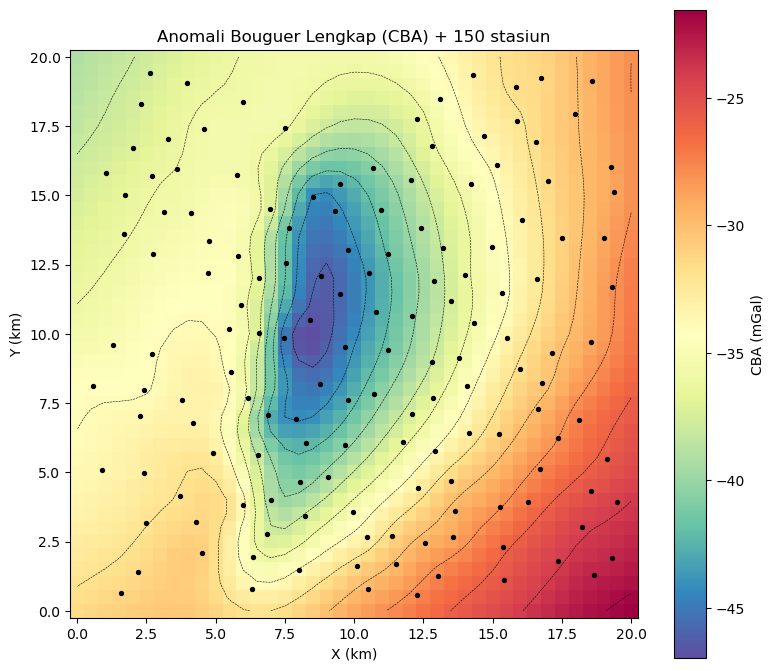

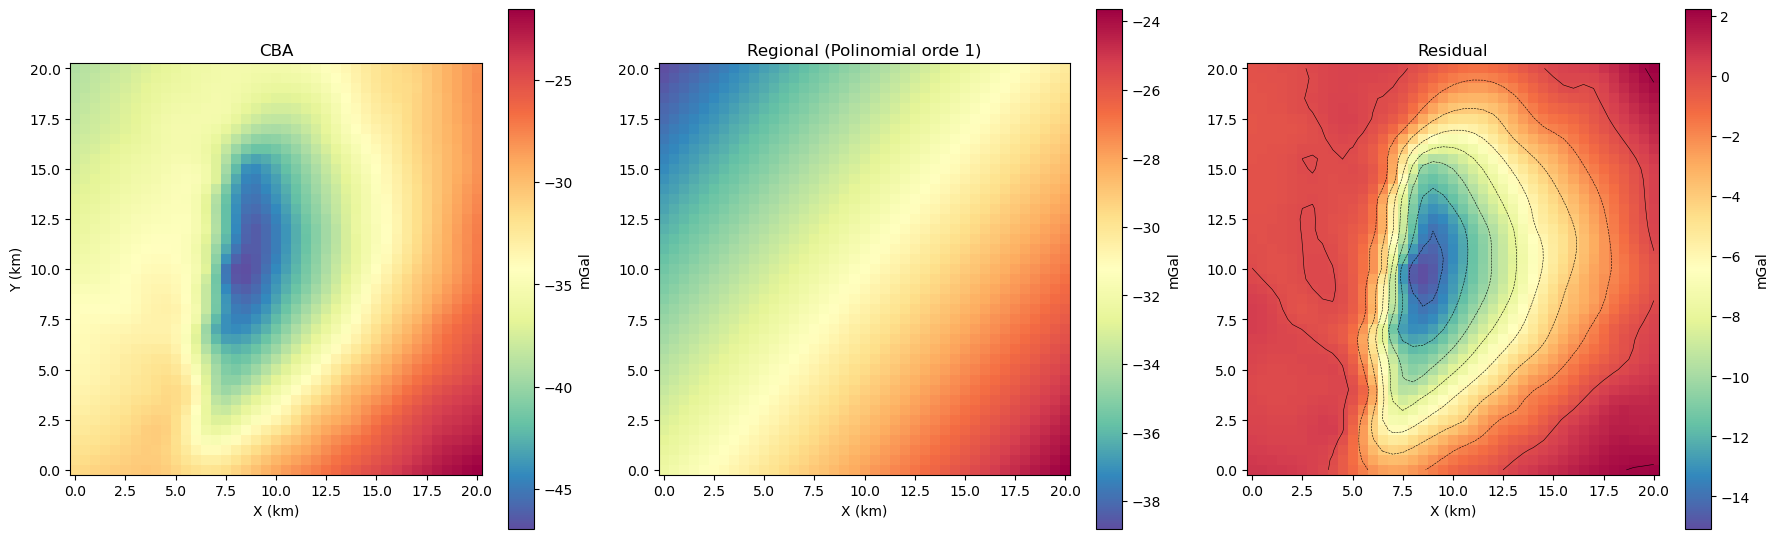

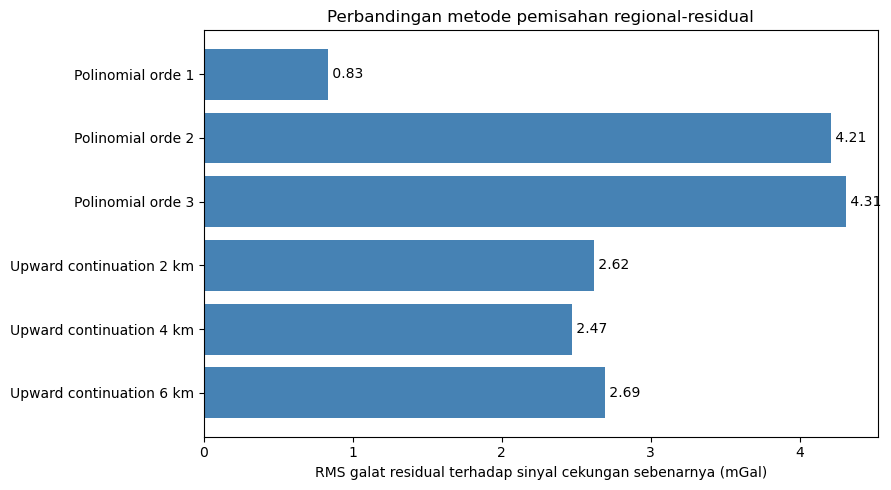

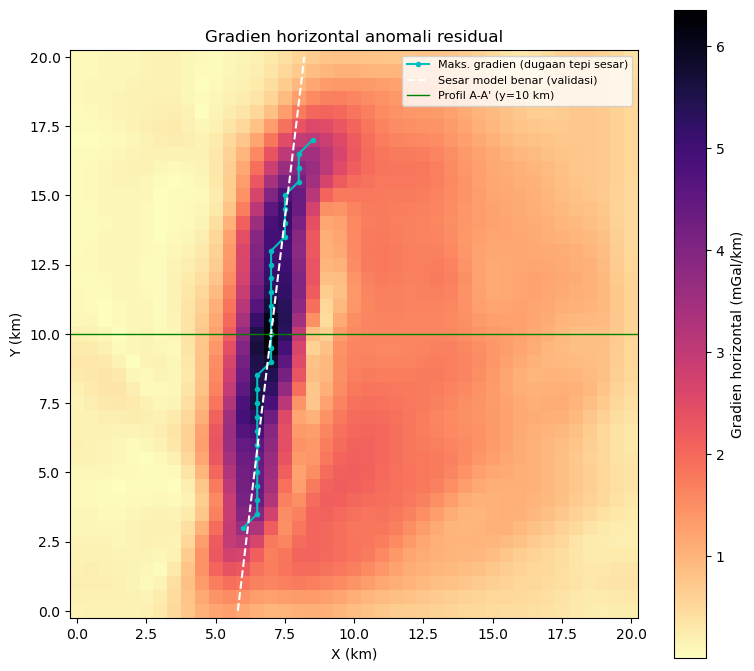

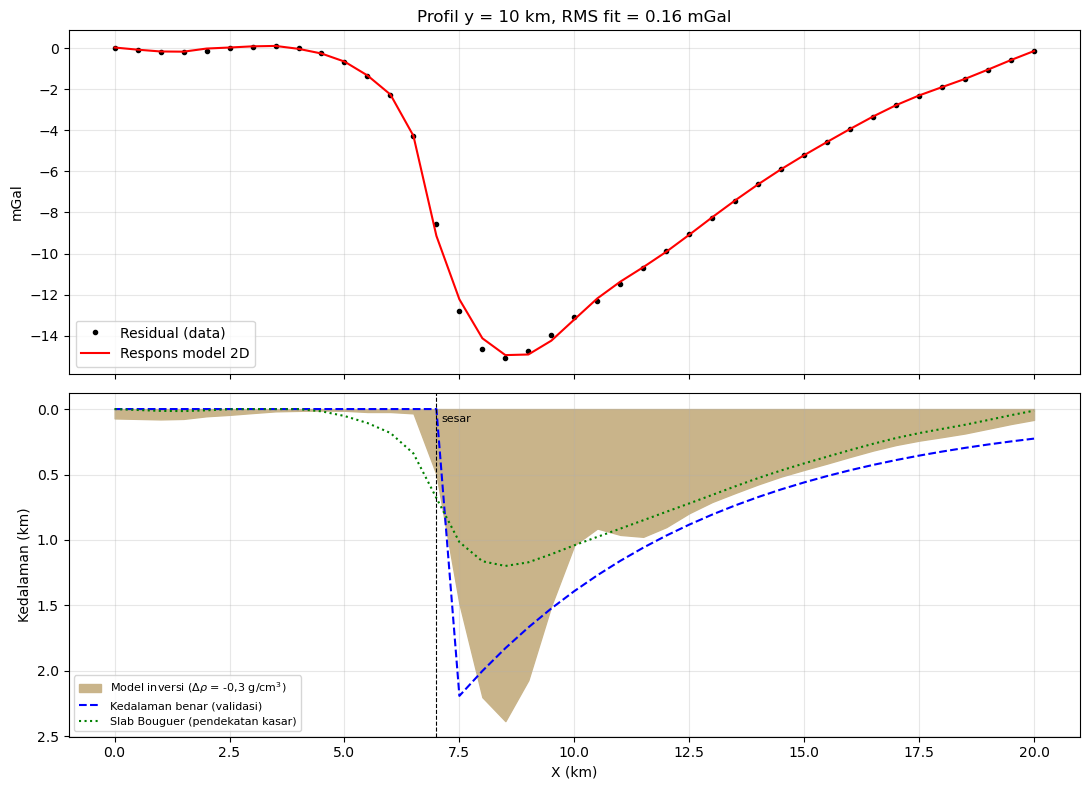

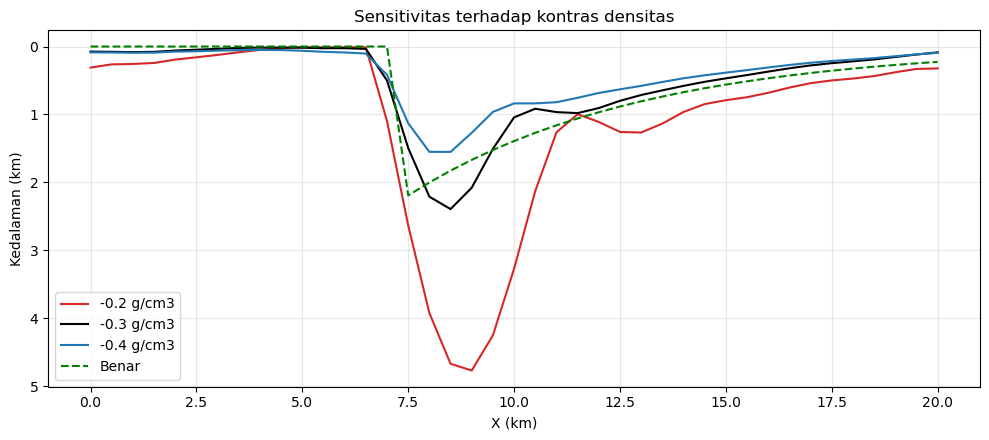

In [32]:
# ------------------------------------------------------------ gambar
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.pcolormesh(GX / 1000, GY / 1000, CBA_grid, cmap="Spectral_r", shading="auto")
ax.scatter(sx / 1000, sy / 1000, c="k", s=8); plt.colorbar(im, label="CBA (mGal)")
cs = ax.contour(GX / 1000, GY / 1000, CBA_grid, 12, colors="k", linewidths=.4)
ax.set_aspect("equal"); ax.set_xlabel("X (km)"); ax.set_ylabel("Y (km)"); ax.set_title("Anomali Bouguer Lengkap (CBA) + 150 stasiun")
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "01_peta_CBA.png"), dpi=130); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(18, 5.5))
for a, (g_, t_) in zip(axs, [(CBA_grid, "CBA"), (reg, f"Regional ({CHOSEN})"), (res, "Residual")]):
    im = a.pcolormesh(GX / 1000, GY / 1000, g_, cmap="Spectral_r", shading="auto"); plt.colorbar(im, ax=a, label="mGal")
    a.set_aspect("equal"); a.set_title(t_); a.set_xlabel("X (km)")
axs[2].contour(GX / 1000, GY / 1000, res, 10, colors="k", linewidths=.4)
axs[0].set_ylabel("Y (km)"); fig.tight_layout(); fig.savefig(os.path.join(HASIL, "02_regional_residual.png"), dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(9, 5)); names = list(meth.metode)
ax.barh(names, meth.RMS_vs_sinyal_cekungan_mGal, color="steelblue"); ax.invert_yaxis()
ax.set_xlabel("RMS galat residual terhadap sinyal cekungan sebenarnya (mGal)"); ax.set_title("Perbandingan metode pemisahan regional-residual")
for i, v in enumerate(meth.RMS_vs_sinyal_cekungan_mGal): ax.text(v, i, f" {v:.2f}", va="center")
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "03_perbandingan_metode.png"), dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.pcolormesh(GX / 1000, GY / 1000, HG, cmap="magma_r", shading="auto"); plt.colorbar(im, label="Gradien horizontal (mGal/km)")
ax.plot(fe.x_maks_gradien_m / 1000, fe.y_m / 1000, "c.-", label="Maks. gradien (dugaan tepi sesar)")
yy = np.linspace(0, 20000, 50); ax.plot(fault_x(yy) / 1000, yy / 1000, "w--", label="Sesar model benar (validasi)")
ax.axhline(10, color="g", lw=1, label="Profil A-A' (y=10 km)"); ax.legend(loc="upper right", fontsize=8)
ax.set_aspect("equal"); ax.set_xlabel("X (km)"); ax.set_ylabel("Y (km)"); ax.set_title("Gradien horizontal anomali residual")
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "04_gradien_horizontal.png"), dpi=130); plt.show()

fig, axs = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
axs[0].plot(gx / 1000, obs_res, "ko", ms=3, label="Residual (data)"); axs[0].plot(gx / 1000, pred_inv, "r-", label="Respons model 2D")
axs[0].set_ylabel("mGal"); axs[0].legend(); axs[0].grid(alpha=.3); axs[0].set_title(f"Profil y = 10 km, RMS fit = {rms_prof:.2f} mGal")
axs[1].fill_between(gx / 1000, 0, d_inv / 1000, color="#c9b48a", label=r"Model inversi ($\Delta\rho$ = -0,3 g/cm$^3$)")
axs[1].plot(gx / 1000, d_true_prof / 1000, "b--", label="Kedalaman benar (validasi)")
axs[1].plot(gx / 1000, slab / 1000, "g:", label="Slab Bouguer (pendekatan kasar)")
axs[1].axvline(fault_x(10000) / 1000, color="k", ls="--", lw=.8); axs[1].text(fault_x(10000) / 1000 + .1, .1, "sesar", fontsize=8)
axs[1].invert_yaxis(); axs[1].set_ylabel("Kedalaman (km)"); axs[1].set_xlabel("X (km)"); axs[1].legend(fontsize=8); axs[1].grid(alpha=.3)
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "05_profil_model_2D.png"), dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
for dr, c in zip((-200.0, -300.0, -400.0), ("tab:red", "k", "tab:blue")):
    ax.plot(gx / 1000, sens_depths[dr] / 1000, color=c, label=f"{dr/1000:.1f} g/cm3")
ax.plot(gx / 1000, d_true_prof / 1000, "g--", label="Benar"); ax.invert_yaxis()
ax.set_xlabel("X (km)"); ax.set_ylabel("Kedalaman (km)"); ax.legend(); ax.grid(alpha=.3); ax.set_title("Sensitivitas terhadap kontras densitas")
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "06_sensitivitas_densitas.png"), dpi=130); plt.show()

In [33]:
# ------------------------------------------------------------ ringkasan anomali
imin = np.unravel_index(np.argmin(res), res.shape)
print("\nPerbandingan metode:\n", meth.round(3).to_string(index=False))
print("\nResidual (orde 1): min %.2f mGal di (x=%.1f km, y=%.1f km); maks %.2f mGal" %
      (res.min(), GX[imin] / 1000, GY[imin] / 1000, res.max()))
print("Gradien horizontal: maks %.2f mGal/km di (x=%.1f, y=%.1f km); rata2 sepanjang jejak %.2f" %
      (HG.max(), GX[np.unravel_index(np.argmax(HG), HG.shape)] / 1000, GY[np.unravel_index(np.argmax(HG), HG.shape)] / 1000, fe.HG_mGal_per_km.mean()))
print("\nJejak sesar (gradien):\n", fe.round(0).to_string(index=False))
print("\nSensitivitas:\n", sens.round(2).to_string(index=False))
print("\nKedalaman model profil: maks %.0f m pada x=%.1f km; slab maks %.0f m; benar maks %.0f m" %
      (d_inv.max(), gx[np.argmax(d_inv)] / 1000, slab.max(), d_true_prof.max()))
print("Lebar zona cekungan (d>200 m) pada profil: dari x=%.1f ke %.1f km" % (gx[d_inv > 200].min() / 1000, gx[d_inv > 200].max() / 1000))
print("Amplitudo regional pada CBA: %.1f hingga %.1f mGal" % (reg.min(), reg.max()))

# RMS fit tiap skenario kontras densitas (bukti bahwa semua skenario sama-sama cocok dengan data -> non-unik)
for dr in (-200.0, -300.0, -400.0):
    pr = forward_2d(sens_depths[dr], dr, gx); pr -= np.median(pr[:8])
    print("RMS fit kontras %.1f g/cm3 = %.3f mGal" % (dr / 1000, np.sqrt(np.mean((pr - obs_res) ** 2))))


Perbandingan metode:
                   metode  RMS_vs_sinyal_cekungan_mGal  residual_min_mGal  residual_maks_mGal  korelasi
       Polinomial orde 1                        0.835            -11.300               5.996     0.980
       Polinomial orde 2                        4.213            -10.334               5.171     0.296
       Polinomial orde 3                        4.310            -10.021               5.148     0.267
Upward continuation 2 km                        2.619             -7.483               5.040     0.819
Upward continuation 4 km                        2.472             -9.916               7.805     0.804
Upward continuation 6 km                        2.693            -11.012               9.594     0.783

Residual (orde 1): min -15.08 mGal di (x=8.5 km, y=10.0 km); maks 2.21 mGal
Gradien horizontal: maks 6.35 mGal/km di (x=7.0, y=10.0 km); rata2 sepanjang jejak 4.89

Jejak sesar (gradien):
     y_m  x_maks_gradien_m  HG_mGal_per_km  x_sesar_benar_m  selisi

## **Interpretasi**
**Pola anomali.** Anomali Bouguer rendah (−46,7 mGal) membentuk jalur memanjang ± utara–selatan di bagian tengah–timur, dibatasi di barat oleh gradien curam dan di timur oleh kenaikan landai ke nilai latar. Pola asimetris ini khas **cekungan setengah-graben**: tepi curam (sesar normal) di satu sisi, sisi lain miring landai.

**Pilihan metode regional.** Orde 1 jauh paling baik (RMS 0,84 mGal; korelasi 0,98). Orde 2 dan 3 buruk (RMS 4,2–4,3 mGal; korelasi hanya 0,27–0,30) karena panjang gelombang cekungan (±12–14 km) mendekati panjang gelombang polinomial sehingga polinomial **ikut menyerap sinyal cekungan**. *Upward continuation* 2/4/6 km (RMS 2,5–2,7 mGal) juga meloloskan sebagian regional dan membuang sebagian sinyal cekungan lebar. Jadi sifat regional harus dipertimbangkan: bila regional memang landai di seluruh 20 km, trend orde rendah adalah pilihan yang masuk akal. Pada data nyata, pilihan ini tidak dapat diverifikasi dengan sinyal benar, sehingga kepekaan terhadap metode harus ditunjukkan, bukan disembunyikan.

**Sesar.** Gradien horizontal maksimum membentuk jejak yang hampir lurus berarah utara–selatan (sedikit miring ke timur ke arah utara) dan berimpit dengan sesar model dalam ±229 m (kurang dari satu sel grid). Puncak gradien 6,35 mGal/km di tengah dan melemah ke ujung, sesuai bahwa cekungan menipis di ujung-ujungnya. Ini *kemungkinan* tepi sesar normal; gradien yang tinggi saja belum pasti sesar (bisa juga batas litologi atau tepi intrusi).

**Kedalaman dan bentuk cekungan.** Profil y = 10 km turun dari ≈ −0,7 mGal (x = 5 km) ke −15 mGal (x = 8,5 km) — sekitar 4 mGal/km — lalu naik landai ke ≈ 0 pada x = 20 km. Model 2D (Δρ = −0,3) menghasilkan kedalaman maksimum ≈ 2,4 km pada x = 8,5 km. Perbandingan dengan model benar menunjukkan keterbatasan: letak kedalaman maksimum bergeser ±1 km ke timur dari titik benar (≈ 7,5 km), tepi sesar tampak sebagai lereng, bukan tebing, dan sisi timur terlalu dangkal (pada x = 12 km ≈ 0,8 km vs ≈ 1,0 km). Sebabnya: gravitasi tidak unik, dan model 2D diterapkan pada benda 3D yang menipis ke utara dan selatan. Slab Bouguer sederhana (1,2 km) meremehkan kedalaman sekitar 50% karena cekungan berdimensi terbatas.

**Ambiguitas dan sensitivitas.** Kedalaman bergantung kuat pada Δρ: −0,2 → 4,8 km (≈ ×2,0), −0,3 → 2,4 km, −0,4 → 1,6 km (×0,65). Perubahan ±0,1 g/cm³ mengubah kedalaman lebih besar daripada kebalikan sederhana, karena kontras dan geometri saling menukar (*trade-off*). Ketiganya cocok dengan data (RMS 0,09–0,40 mGal), sehingga data **tidak** dapat menentukan Δρ dan kedalaman sekaligus. Pernyataan "cekungan sedalam ±2,4 km" hanya sah dengan asumsi Δρ = −0,3 g/cm³; jangkauan wajar 1,6–4,8 km.


# **Kasus 4 — Magnetik — Tubuh Batuan Ultramafik di Lintang Rendah**

## Data dan metode
- 400 titik (grid 20 × 20, spasi 50 m, area ≈ 1 × 1 km): `x, y, elevasi, waktu, T_observasi` (`data/data_magnetik_sintetis.csv`) + stasiun basis tiap menit (`data/data_stasiun_basis.csv`). Akuisisi zig-zag, 28 detik/titik (±3 jam 07 menit).
- **IGRF ilustratif:** F = 41.000 nT, I = −20°, D = 1° (+ gradien lokal), harus disesuaikan dengan lokasi/tanggal survei. Nilai observasi mentah tidak diubah.
- Koreksi: (1) variasi harian dari stasiun basis (interpolasi waktu), (2) pengurangan IGRF → anomali medan total dT.
- RTP di domain Fourier (*padding* cermin); dua versi: **tanpa stabilisasi** dan **stabil** (operator Wiener-type, parameter damping 0,15, sengaja disebutkan). Pembanding: **sinyal analitik** (√(dx² + dy² + dz²)), tidak bergantung arah magnetisasi.
- Zona anomali: sinyal analitik ≥ 30% maksimum; keyakinan dari skor 0–4 (SNR sinyal analitik ≥ 10, luas ≥ 8 sel, selisih puncak RTP–pusat AS ≤ 100 m, amplitudo RTP ≥ 15 nT): 4 = tinggi, 2–3 = sedang, ≤ 1 = rendah.
- Model sumber (hanya pembangkit data): dua lensa magnetik termagnetisasi induksi, suseptibilitas **asumsi** 0,05 dan 0,03 SI. **Suseptibilitas tidak diestimasi dari data.**

Kode: `kasus4_magnetik.py`.

In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import ndimage

BASE = os.path.join(os.getcwd(), "kasus_4_magnetik")
DATA, HASIL = os.path.join(BASE, "data"), os.path.join(BASE, "hasil")
os.makedirs(DATA, exist_ok=True); os.makedirs(HASIL, exist_ok=True)
rng = np.random.default_rng(61241070)

F0, INC, DEC = 41000.0, -20.0, 1.0           # IGRF ilustratif
MU0 = 4e-7 * np.pi
def fvec(inc, dec):                          # (E, N, Up)
    i, d = np.radians(inc), np.radians(dec)
    return np.array([np.cos(i) * np.sin(d), np.cos(i) * np.cos(d), -np.sin(i)])

In [35]:
# ------------------------------------------------------------ model benar: dua tubuh ultramafik
CUBE = 10.0
def body_cubes(cx, cy, L, W, az_deg, z_top, z_bot):
    """Kumpulan kubus 10 m untuk tubuh lensa memanjang azimuth az (dari Utara searah jarum jam)."""
    u = np.arange(-L / 2 + CUBE / 2, L / 2, CUBE); v = np.arange(-W / 2 + CUBE / 2, W / 2, CUBE)
    z = np.arange(z_bot + CUBE / 2, z_top, CUBE)
    U, V, Z = np.meshgrid(u, v, z, indexing="ij")
    # bentuk lensa: lebar menyempit ke ujung
    keep = (np.abs(V) <= (W / 2) * np.sqrt(np.clip(1 - (2 * U / L) ** 2, 0, None)))
    a = np.radians(az_deg)
    E = cx + U * np.sin(a) + V * np.cos(a); N = cy + U * np.cos(a) - V * np.sin(a)
    return np.c_[E[keep], N[keep], Z[keep]]

bodies = {
    "A": dict(cx=560, cy=520, L=380, W=90, az=40, ztop=108, zbot=-40, kappa=0.050),
    "B": dict(cx=250, cy=230, L=140, W=110, az=100, ztop=105, zbot=20, kappa=0.030),
}
f_hat = fvec(INC, DEC)
def forward_dipoles(obs, srcs, kappa, inc=INC, dec=DEC, F=F0):
    fh = fvec(inc, dec)
    M = kappa * F * 1e-9 / MU0                                # A/m (magnetisasi induksi)
    m = (M * CUBE**3) * fh                                    # momen tiap kubus (A.m2)
    out = np.zeros(len(obs))
    for k in range(0, len(srcs), 800):
        r = obs[:, None, :] - srcs[None, k:k + 800, :]
        rn = np.linalg.norm(r, axis=2); rh = r / rn[..., None]
        mdr = rh @ m
        B = 1e-7 * (3 * mdr[..., None] * rh - m[None, None, :]) / rn[..., None] ** 3
        out += (B @ fh).sum(axis=1) * 1e9
    return out

In [36]:
# ------------------------------------------------------------ geometri survei
nx = ny = 20; dx = 50.0
gxs = np.arange(nx) * dx; gys = np.arange(ny) * dx
GX, GY = np.meshgrid(gxs, gys)                                 # GX[j,i]
elev = 120 + 8 * np.sin(GX / 260) + 6 * np.cos(GY / 310)       # elevasi tanah (m)
sensor_z = elev + 1.5
obs_xyz = np.c_[GX.ravel(), GY.ravel(), sensor_z.ravel()]

def total_anomaly(inc=INC, dec=DEC):
    a = np.zeros(len(obs_xyz))
    for b in bodies.values():
        a += forward_dipoles(obs_xyz, body_cubes(b["cx"], b["cy"], b["L"], b["W"], b["az"], b["ztop"], b["zbot"]),
                             b["kappa"], inc, dec)
    return a
anom_true = total_anomaly()
anom_true_pole = total_anomaly(90.0, 0.0)                       # untuk validasi RTP

In [37]:
# ------------------------------------------------------------ waktu, variasi harian, IGRF, noise
t0 = 8.0                                                        # jam
# jalur akuisisi zig-zag per lintasan (arah timur-barat bergantian)
order = []
for j in range(ny):
    cols = range(nx) if j % 2 == 0 else range(nx - 1, -1, -1)
    order += [j * nx + i for i in cols]
t_idx = np.empty(nx * ny); t_idx[order] = np.arange(nx * ny)
t_hr = t0 + t_idx * 28.0 / 3600.0                               # 28 detik per titik
def diurnal(th):                                                # nT, variasi harian ilustratif
    return 14 * np.sin(2 * np.pi * (th - t0) / 7.0) + 5 * np.sin(2 * np.pi * (th - t0) / 1.3 + 1.0)
igrf = F0 + 0.004 * (obs_xyz[:, 1] - 500) + 0.002 * (obs_xyz[:, 0] - 500)     # gradien lokal IGRF
noise = 1.0 * rng.standard_normal(nx * ny)
T_obs = igrf + diurnal(t_hr) + anom_true + noise

tb = np.arange(t0, t0 + nx * ny * 28 / 3600 + 0.01, 1 / 60)
T_base = F0 + diurnal(tb) + 0.3 * rng.standard_normal(len(tb))
df = pd.DataFrame(dict(id=np.arange(1, 401), x_m=obs_xyz[:, 0], y_m=obs_xyz[:, 1], elevasi_m=elev.ravel().round(1),
                       waktu_jam=t_hr.round(4), T_obs_nT=T_obs.round(2)))
df.to_csv(os.path.join(DATA, "data_magnetik_sintetis.csv"), index=False)
pd.DataFrame(dict(waktu_jam=tb.round(4), T_base_nT=T_base.round(2))).to_csv(os.path.join(DATA, "data_stasiun_basis.csv"), index=False)

In [38]:
# ------------------------------------------------------------ koreksi
base_interp = np.interp(t_hr, tb, T_base)
diur_corr = base_interp - F0                                    # variasi harian (nT) relatif terhadap IGRF basis
T_corr = T_obs - diur_corr
dT = T_corr - igrf                                              # anomali medan total
dT_grid = dT.reshape(ny, nx)
err_dT = dT - anom_true
print("Variasi harian: %.1f s/d %.1f nT" % (diur_corr.min(), diur_corr.max()))
print("T_obs: %.1f - %.1f nT | Anomali dT: min %.1f maks %.1f nT, std %.1f nT" % (T_obs.min(), T_obs.max(), dT.min(), dT.max(), dT.std()))
print("RMS galat dT vs anomali benar: %.2f nT" % np.sqrt(np.mean(err_dT ** 2)))
print("Tanpa koreksi harian: RMS galat %.2f nT" % np.sqrt(np.mean((T_obs - igrf - anom_true) ** 2)))

Variasi harian: 3.2 s/d 18.9 nT
T_obs: 40713.2 - 41287.5 nT | Anomali dT: min -305.0 maks 277.9 nT, std 54.8 nT
RMS galat dT vs anomali benar: 1.08 nT
Tanpa koreksi harian: RMS galat 11.16 nT


In [39]:
# ------------------------------------------------------------ FFT: RTP, sinyal analitik
PAD = 22
def fft_prep(g):
    gp = np.pad(g - g.mean(), PAD, mode="reflect")
    ky = np.fft.fftfreq(gp.shape[0], dx) * 2 * np.pi; kx = np.fft.fftfreq(gp.shape[1], dx) * 2 * np.pi
    KX, KY = np.meshgrid(kx, ky); K = np.hypot(KX, KY); K[0, 0] = 1e-12
    return gp, KX, KY, K
def crop(a): return a[PAD:-PAD, PAD:-PAD]

def rtp(g, inc=INC, dec=DEC, damping=None):
    gp, KX, KY, K = fft_prep(g)
    fh = fvec(inc, dec)                                         # (E,N,Up); magnetisasi = medan (induksi)
    Th = -fh[2] + 1j * (fh[0] * KX + fh[1] * KY) / K              # komponen vertikal ke BAWAH (sin I)
    D = Th * Th
    H = 1.0 / D if damping is None else np.conj(D) / (np.abs(D) ** 2 + damping ** 2)
    H[0, 0] = 0
    return crop(np.real(np.fft.ifft2(np.fft.fft2(gp) * H)))

def analytic_signal(g):
    gp, KX, KY, K = fft_prep(g)
    F = np.fft.fft2(gp)
    gx_ = crop(np.real(np.fft.ifft2(1j * KX * F))); gy_ = crop(np.real(np.fft.ifft2(1j * KY * F)))
    gz_ = crop(np.real(np.fft.ifft2(K * F)))
    return np.sqrt(gx_**2 + gy_**2 + gz_**2)

DAMP = 0.15                                                     # parameter stabilisasi RTP
rtp_raw = rtp(dT_grid)
rtp_stab = rtp(dT_grid, damping=DAMP)
AS = analytic_signal(dT_grid)
# referensi sintetis: anomali di kutub (I=90) = jawaban RTP ideal
pole = anom_true_pole.reshape(ny, nx)
def stats(a, ref):
    a = a - a.mean(); r = ref - ref.mean()
    return np.sqrt(np.mean((a - r) ** 2)), np.corrcoef(a.ravel(), r.ravel())[0, 1]
rows = []
for nm, a in [("dT (anomali total, I=-20)", dT_grid), ("RTP tanpa stabilisasi", rtp_raw), (f"RTP stabil (damping {DAMP})", rtp_stab)]:
    e, c = stats(a, pole); rows.append(dict(peta=nm, min_nT=a.min(), maks_nT=a.max(), RMS_vs_anomali_kutub_nT=e, korelasi=c))
rt = pd.DataFrame(rows); rt.round(2).to_csv(os.path.join(HASIL, "perbandingan_RTP.csv"), index=False)

# kebisingan sinyal analitik dari realisasi noise saja
AS_noise = analytic_signal(rng.standard_normal((ny, nx)))
sigma_AS = np.median(AS_noise)
print("\nPerbandingan RTP:\n", rt.round(2).to_string(index=False))
print("AS: maks %.2f nT/m ; median noise-only %.3f nT/m" % (AS.max() * 1 / 1, sigma_AS))


Perbandingan RTP:
                      peta  min_nT  maks_nT  RMS_vs_anomali_kutub_nT  korelasi
dT (anomali total, I=-20) -304.97   277.86                   131.81     -0.47
    RTP tanpa stabilisasi -108.92   751.58                    36.66      0.95
RTP stabil (damping 0.15)  -67.02   601.99                    21.83      0.98
AS: maks 9.48 nT/m ; median noise-only 0.062 nT/m


In [40]:
# ------------------------------------------------------------ ekstraksi zona anomali
thr = 0.30 * AS.max()
lab, nlab = ndimage.label(AS >= thr)
zones = []
for k in range(1, nlab + 1):
    m = lab == k
    n_cell = int(m.sum())
    if n_cell < 3: continue
    yy, xx = np.nonzero(m); wts = AS[m]
    cx, cy = (xx * dx * wts).sum() / wts.sum(), (yy * dx * wts).sum() / wts.sum()
    pts = np.c_[xx * dx, yy * dx] - [cx, cy]
    ev, evec = np.linalg.eigh(np.cov(pts.T)) if n_cell > 3 else (np.array([1, 1]), np.eye(2))
    v = evec[:, -1]; az = np.degrees(np.arctan2(v[0], v[1])) % 180
    elong = float(np.sqrt(ev[-1] / max(ev[0], 1e-6)))
    peak_rtp_cell = np.unravel_index(np.argmax(np.where(m, rtp_stab, -1e9)), AS.shape)
    # kemenerusan (panjang) dari rentang sepanjang sumbu utama
    proj = pts @ v; length = proj.max() - proj.min() + dx
    rtp_amp = rtp_stab[m].max() - np.median(rtp_stab[~(ndimage.binary_dilation(lab > 0, iterations=3))])
    snr = AS[m].max() / sigma_AS
    # tingkat keyakinan (aturan eksplisit): SNR, luasan, kesesuaian posisi puncak RTP vs pusat AS
    d_pos = np.hypot(peak_rtp_cell[1] * dx - cx, peak_rtp_cell[0] * dx - cy)
    score = int(snr >= 10) + int(n_cell >= 8) + int(d_pos <= 100) + int(rtp_amp >= 15)
    conf = "tinggi" if score >= 4 else ("sedang" if score >= 2 else "rendah")
    zones.append(dict(zona=0, x_pusat_m=cx, y_pusat_m=cy, luas_m2=n_cell * dx * dx, panjang_m=length, azimuth_deg=az,
                      elongasi=elong, AS_maks_nT_per_m=AS[m].max(), SNR_AS=snr,
                      dT_min_nT=dT_grid[m].min(), dT_maks_nT=dT_grid[m].max(), RTP_amplitudo_nT=rtp_amp,
                      jarak_puncakRTP_ke_pusatAS_m=d_pos, skor=int(score), keyakinan=conf))
zn = pd.DataFrame(zones).sort_values("AS_maks_nT_per_m", ascending=False).reset_index(drop=True)
zn["zona"] = [f"Z{i+1}" for i in range(len(zn))]
zn.round(2).to_csv(os.path.join(HASIL, "zona_anomali.csv"), index=False)
truth = pd.DataFrame([dict(tubuh=k, x_m=b["cx"], y_m=b["cy"], panjang_m=b["L"], azimuth_deg=b["az"] % 180, kappa_asumsi_SI=b["kappa"],
                           kedalaman_atas_m=130 - b["ztop"], ) for k, b in bodies.items()])
truth.to_csv(os.path.join(HASIL, "model_benar_sintetis.csv"), index=False)
print("\nZona anomali (AS >= %.2f nT/m):\n" % thr, zn.round(1).to_string(index=False))
print("\nModel benar:\n", truth.to_string(index=False))


Zona anomali (AS >= 2.85 nT/m):
 zona  x_pusat_m  y_pusat_m  luas_m2  panjang_m  azimuth_deg  elongasi  AS_maks_nT_per_m  SNR_AS  dT_min_nT  dT_maks_nT  RTP_amplitudo_nT  jarak_puncakRTP_ke_pusatAS_m  skor keyakinan
  Z1      579.3      541.4  70000.0      479.4         32.1       2.6               9.5   153.6     -305.0       277.9             616.5                          50.8     4    tinggi
  Z2      241.7      234.8  15000.0      161.8        153.4       1.1               4.0    64.1     -133.3        96.3             226.3                          17.3     3    sedang

Model benar:
 tubuh  x_m  y_m  panjang_m  azimuth_deg  kappa_asumsi_SI  kedalaman_atas_m
    A  560  520        380           40             0.05                22
    B  250  230        140          100             0.03                25


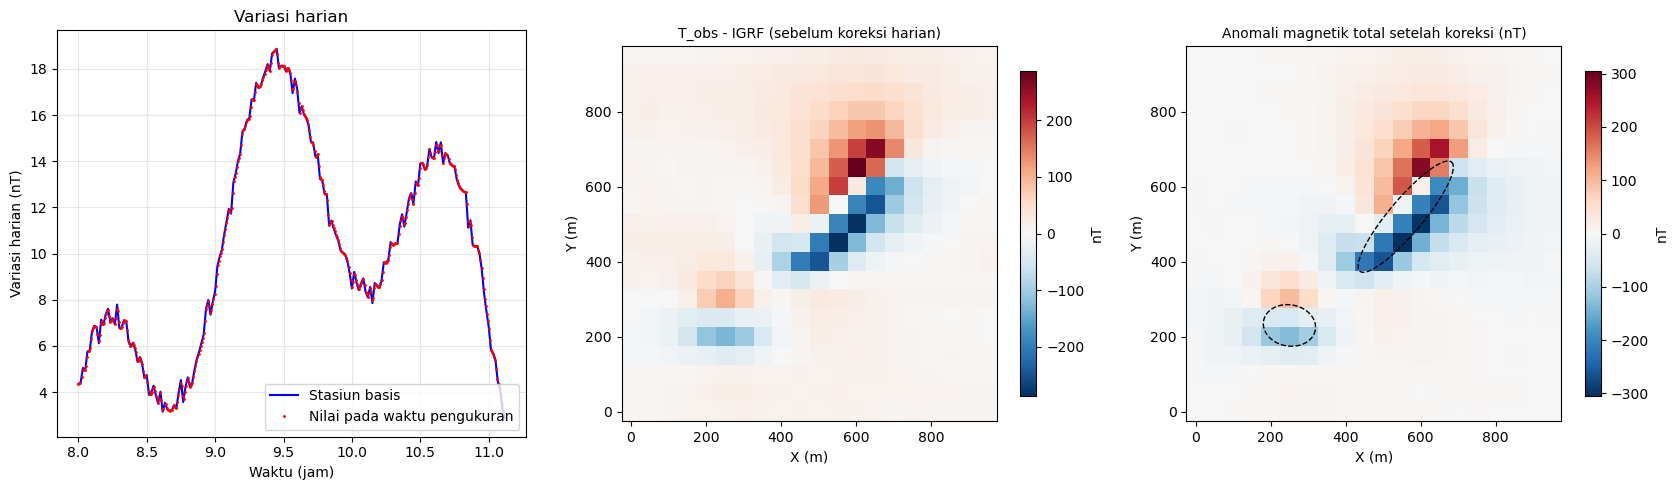

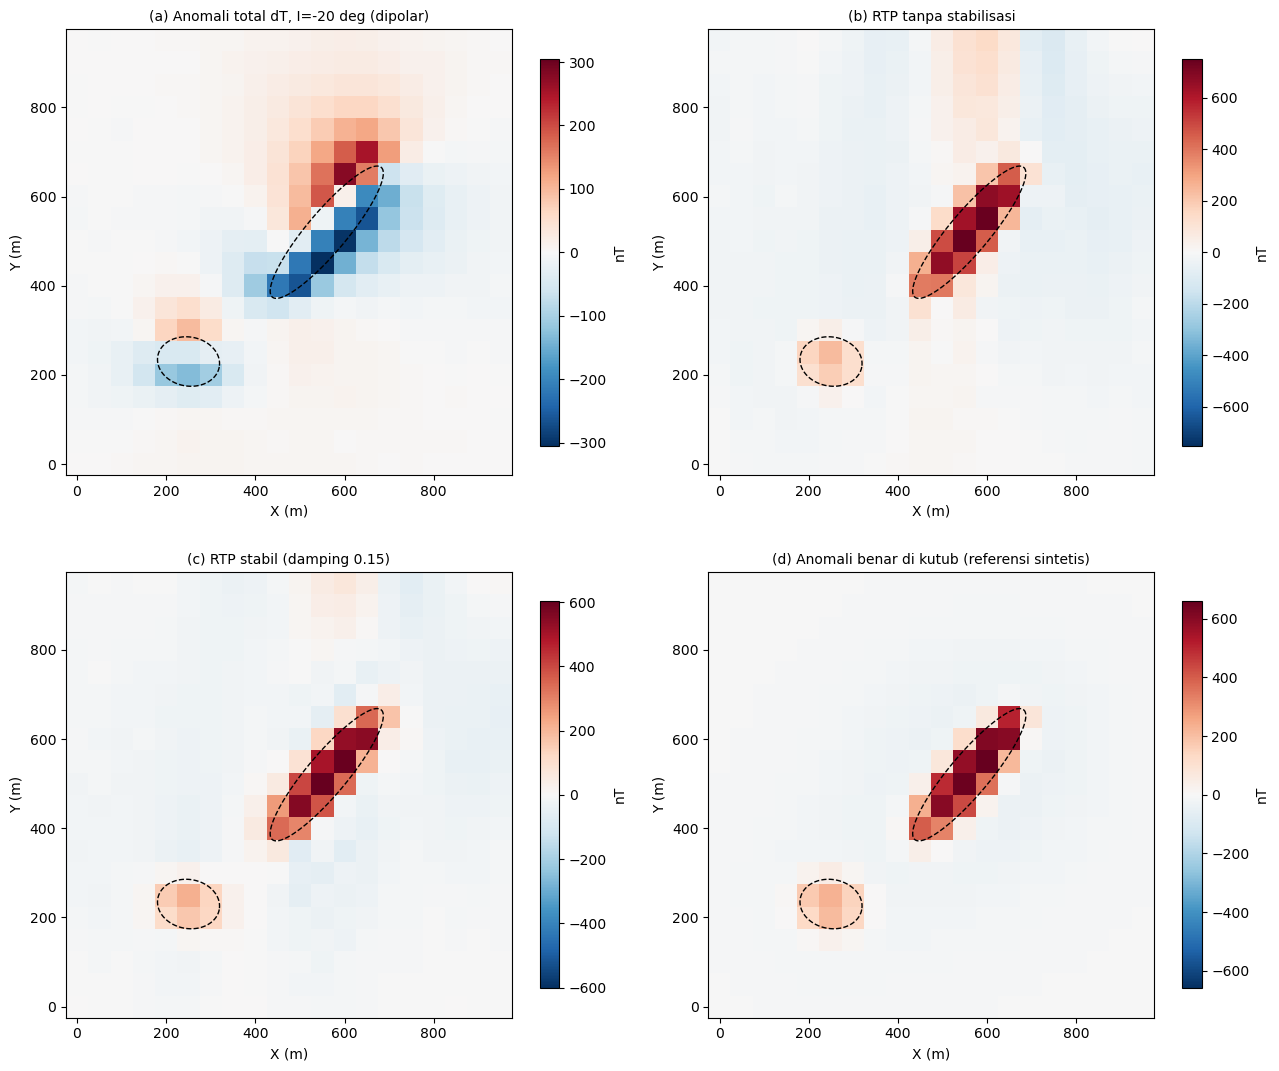

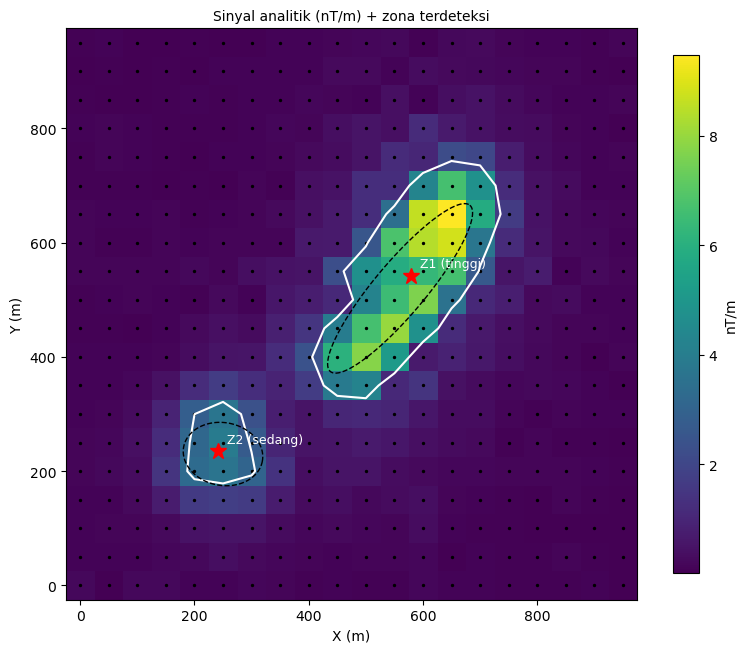

In [41]:
# ------------------------------------------------------------ gambar
ext = [-dx / 2, (nx - .5) * dx, -dx / 2, (ny - .5) * dx]
def mp(ax, a, ttl, cmap="RdBu_r", sym=True, label="nT"):
    v = np.abs(a).max() if sym else None
    im = ax.imshow(a, origin="lower", extent=ext, cmap=cmap, vmin=-v if sym else None, vmax=v)
    plt.colorbar(im, ax=ax, label=label, shrink=.8); ax.set_title(ttl, fontsize=10); ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)")
    return im
def outline(ax):
    for k, b in bodies.items():
        a = np.radians(b["az"]); t = np.linspace(0, 2 * np.pi, 100)
        u, v = b["L"] / 2 * np.cos(t), b["W"] / 2 * np.sin(t)
        ax.plot(b["cx"] + u * np.sin(a) + v * np.cos(a), b["cy"] + u * np.cos(a) - v * np.sin(a), "k--", lw=1)

fig, axs = plt.subplots(1, 3, figsize=(17, 5))
axs[0].plot(tb, T_base - F0, "b-", label="Stasiun basis"); axs[0].plot(t_hr, diur_corr, "r.", ms=2, label="Nilai pada waktu pengukuran")
axs[0].set_xlabel("Waktu (jam)"); axs[0].set_ylabel("Variasi harian (nT)"); axs[0].legend(); axs[0].grid(alpha=.3); axs[0].set_title("Variasi harian")
mp(axs[1], (T_obs - igrf).reshape(ny, nx), "T_obs - IGRF (sebelum koreksi harian)")
mp(axs[2], dT_grid, "Anomali magnetik total setelah koreksi (nT)"); outline(axs[2])
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "01_koreksi_dan_anomali.png"), dpi=130); plt.show()

fig, axs = plt.subplots(2, 2, figsize=(13, 11))
mp(axs[0, 0], dT_grid, "(a) Anomali total dT, I=-20 deg (dipolar)"); outline(axs[0, 0])
mp(axs[0, 1], rtp_raw, "(b) RTP tanpa stabilisasi"); outline(axs[0, 1])
mp(axs[1, 0], rtp_stab, f"(c) RTP stabil (damping {DAMP})"); outline(axs[1, 0])
mp(axs[1, 1], pole, "(d) Anomali benar di kutub (referensi sintetis)"); outline(axs[1, 1])
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "02_RTP_perbandingan.png"), dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
mp(ax, AS, "Sinyal analitik (nT/m) + zona terdeteksi", cmap="viridis", sym=False, label="nT/m")
ax.contour(np.arange(nx) * dx, np.arange(ny) * dx, AS, [thr], colors="w", linewidths=1.5)
outline(ax)
for _, z in zn.iterrows():
    ax.plot(z.x_pusat_m, z.y_pusat_m, "r*", ms=12); ax.text(z.x_pusat_m + 15, z.y_pusat_m + 15, f"{z.zona} ({z.keyakinan})", color="w", fontsize=9)
ax.scatter(obs_xyz[:, 0], obs_xyz[:, 1], c="k", s=2)
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "03_sinyal_analitik_zona.png"), dpi=130); plt.show()

## **Interpretasi**
**Efek inklinasi rendah.** Pada I = −20°, anomali dT berbentuk pasangan dipol: lobus negatif (−305 nT) menutupi tubuh sumber bagian selatan/tengah dan lobus positif (+278 nT) bergeser ±100–150 m ke utara, di luar sumbernya. Tubuh B kecil juga menampilkan pasangan serupa (−133/+96 nT). Bila peta dT dibaca langsung, posisi tubuh akan salah (puncak positif bukan di atas sumber); karena itu RTP diperlukan. Korelasi dT dengan anomali kutub bahkan negatif (−0,47).

**Hasil RTP.** RTP memusatkan anomali di atas sumber: tanpa stabilisasi, korelasi 0,95 dan RMS 36,7 nT tetapi amplitudo melebihi referensi (752 vs 659 nT) dan muncul artefak negatif (−109 nT) serta bayangan lemah berarah utara–selatan. Versi stabil (damping 0,15) lebih baik: korelasi 0,98, RMS 21,8 nT, artefak turun (−67 nT), tetapi puncak mengecil (602 nT, ≈ 9% terlalu rendah). Jadi stabilisasi menukar *noise/artefak* dengan *redaman amplitudo*. Amplitudo RTP hanya bisa dipakai relatif, tidak dikonversi menjadi suseptibilitas.

**Perbedaan RTP vs sinyal analitik.** Keduanya setuju soal lokasi: puncak RTP terletak 51 m (Z1) dan 17 m (Z2) dari pusat sinyal analitik, kurang dari 2 sel. Sinyal analitik tidak peduli arah magnetisasi dan menonjolkan **tepi** tubuh; RTP bergantung asumsi magnetisasi induksi saja (remanen akan merusak RTP, tidak merusak AS). Karena kedua peta konsisten, peta RTP tidak sekadar artefak operator.

**Zona terdeteksi.**
- **Z1 — keyakinan tinggi (skor 4/4):** pusat (579, 541) m; lensa memanjang ±479 m berarah N32°E (elongasi 2,6) seluas 70.000 m²; amplitudo RTP ≈ 617 nT; SNR sinyal analitik 154. Diduga tubuh batuan termagnetisasi tinggi, cocok dengan ultramafik terserpentinisasi. Terhadap model benar (pusat 560, 520; panjang 380 m; N40°E): pusat meleset ±29 m, azimuth ±8°, panjang berlebih ±100 m (efek ambang 30% dan pelebaran sel 50 m).
- **Z2 — keyakinan sedang (skor 3/4):** pusat (242, 235) m; ±162 m, hampir sama panjang ke segala arah (elongasi ≈ 1,2); amplitudo RTP ≈ 226 nT. Skor tidak penuh karena luasnya hanya 6 sel (< 8). Azimuth 153° pada tabel **tidak bermakna** karena bentuknya hampir bulat. Terhadap model (pusat 250, 230): pusat meleset ±10 m.
- Tidak ada zona rendah; tidak ada anomali sedang-tinggi lain di luar dua zona ini.

**Batas fakta vs dugaan.** Fakta data: dua anomali dengan amplitudo ratusan nT, bentuk dan posisi di atas. Dugaan geologi: bahwa sumbernya batuan ultramafik terserpentinisasi. Alternatif yang tidak dapat dibedakan hanya dari data magnetik: tubuh basalt/gabro kaya magnetit, laterit besi, atau struktur kaya mineral magnetik. Maka kata yang dipakai "diduga/berindikasi".

# **Kasus 5 — Mikrotremor HVSR — Mikrozonasi Tapak**

## Data dan metode
- 20 titik (grid ≈ 4 × 5, area ≈ 1,6 × 1,1 km), tiap titik 30 menit = 36 jendela × 50 s, laju sampling 100 Hz. **Yang disimulasikan adalah kurva HVSR tiap jendela** (bukan rekaman mentah `.mseed`), lengkap dengan variasi antar jendela, sehingga σ(f0) dan σA(f) dapat dihitung. Kurva rata-rata tiap titik disimpan sebagai tabel frekuensi–rasio H/V (`data/kurva_HVSR_sintetis.csv`) dan catatan lapangan di `data/koordinat_catatan_titik.csv`.
- Parameter pengolahan **sama untuk semua titik**: lw = 50 s, nw = 36, *smoothing* Konno–Ohmachi b = 40 (dianggap sudah diterapkan), rentang pencarian puncak 0,4–15 Hz, rata-rata geometrik antar jendela.
- Tiga titik sengaja diberi gangguan: T7 (lalu lintas padat, puncak sempit 8 Hz), T13 (kontras impedansi lemah, kurva datar), T18 (angin kencang).
- Kriteria **SESAME (2004)**: kurva andal (R1–R3: f0 > 10/lw, nc = lw·nw·f0 > 200, σA(f) < 2 untuk 0,5f0–2f0) dan puncak jelas (C1–C6, minimal 5 dari 6: penurunan di bawah A0/2 di kedua sisi, A0 > 2, kestabilan puncak ±σ, σ(f0) < ε(f0)·f0, σA(f0) < θ(f0)).
- Ketebalan sedimen h = Vs/(4·f0) dengan **Vs asumsi 200 m/s (rentang 150–300 m/s)**; indeks kerentanan Kg = A0²/f0 (indikator relatif); zonasi Kg: ≥ 12 tinggi, 4–12 sedang, < 4 rendah (**ambang asumsi**, relatif terhadap sebaran data ini).

Kode: `kasus5_hvsr.py`.

In [42]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

BASE = os.path.join(os.getcwd(), "kasus_5_hvsr")
DATA, HASIL = os.path.join(BASE, "data"), os.path.join(BASE, "hasil")
os.makedirs(DATA, exist_ok=True); os.makedirs(HASIL, exist_ok=True)
rng = np.random.default_rng(61241070)

LW, NW = 50.0, 36                       # panjang jendela (s), jumlah jendela
VS_ASUMSI, VS_MIN, VS_MAX = 200.0, 150.0, 300.0
freq = np.geomspace(0.3, 20, 160)
lnf = np.log(freq)

In [43]:
# ------------------------------------------------------------ geometri titik & model benar
gx, gy = np.meshgrid(np.linspace(100, 1500, 5), np.linspace(100, 1000, 4))
px, py = gx.ravel() + rng.uniform(-40, 40, 20), gy.ravel() + rng.uniform(-40, 40, 20)
def fault_x(y): return 1350 - 0.12 * np.asarray(y)             # jejak sesar (km-an kecil, sisi timur kawasan)
def dist_fault(x, y): return np.abs(x - fault_x(y)) * np.cos(np.arctan(0.12))
dist = dist_fault(px, py)
h_true = 6 + 54 * np.exp(-dist / 480.0) + rng.normal(0, 1.5, 20)       # sedimen menebal mendekati sesar
Vs_true = 170 + 1.6 * h_true
f0_true = Vs_true / (4 * h_true)
A0_true = np.clip(2.4 + 0.045 * h_true + rng.normal(0, 0.5, 20), 2.2, 7.0)

notes = ["cerah, tenang"] * 20
special = {6: ("lalu lintas padat dekat titik", dict(sig=0.40, spur=(8.0, 3.2))),
           12: ("kontras impedansi lemah (kurva datar)", dict(flat=True)),
           17: ("angin kencang", dict(sig=0.55))}
def window_curves(i):
    f0, A0 = f0_true[i], A0_true[i]
    sig = 0.12; spur = None
    if i in special:
        notes[i] = special[i][0]
        sig = special[i][1].get("sig", sig); spur = special[i][1].get("spur")
        if special[i][1].get("flat"): A0 = 1.45
    W = np.empty((NW, len(freq)))
    for w in range(NW):
        fw = f0 * np.exp(rng.normal(0, 0.028 if i not in special else 0.09))
        aw = A0 * np.exp(rng.normal(0, 0.08 if i not in special else 0.25))
        base = 1 + (aw - 1) * np.exp(-0.5 * (np.log(freq / fw) / 0.30) ** 2)
        base = base * (1 - 0.12 * np.exp(-0.5 * (np.log(freq / (3.5 * fw)) / 0.5) ** 2))   # sedikit penurunan di atas puncak
        eps = gaussian_filter1d(rng.standard_normal(len(freq)), 4) * sig * 2.2
        c = base * np.exp(eps)
        if spur:  # puncak sempit akibat sumber industri/lalu lintas, amplitudo bervariasi antar-jendela
            c = c + rng.uniform(0.2, 1.0) * spur[1] * np.exp(-0.5 * (np.log(freq / spur[0]) / 0.04) ** 2)
        W[w] = c
    return W
curves = [window_curves(i) for i in range(20)]

# simpan tabel kurva rata-rata (format input "tabel frekuensi - rasio H/V")
rows = []
for i, W in enumerate(curves):
    m = np.exp(np.log(W).mean(0)); s = np.exp(np.log(W).std(0, ddof=1))
    for f, a, b in zip(freq, m, s): rows.append(dict(titik=i + 1, f_Hz=round(f, 4), HV_rata2=round(a, 4), faktor_sigma=round(b, 4)))
pd.DataFrame(rows).to_csv(os.path.join(DATA, "kurva_HVSR_sintetis.csv"), index=False)
pd.DataFrame(dict(titik=np.arange(1, 21), x_m=px.round(0), y_m=py.round(0), catatan_lapangan=notes)).to_csv(
    os.path.join(DATA, "koordinat_catatan_titik.csv"), index=False)

In [44]:
# ------------------------------------------------------------ analisis + SESAME
def eps_theta(f0):
    if f0 < 0.2: return 0.25, 3.0
    if f0 < 0.5: return 0.20, 2.5
    if f0 < 1.0: return 0.15, 2.0
    if f0 < 2.0: return 0.10, 1.78
    return 0.05, 1.58

res = []
for i, W in enumerate(curves):
    L = np.log(W); mean = np.exp(L.mean(0)); sA = np.exp(L.std(0, ddof=1))
    valid_band = (freq >= 0.4) & (freq <= 15)
    k0 = np.argmax(np.where(valid_band, mean, -1)); f0, A0 = freq[k0], mean[k0]
    f0w = np.array([freq[np.argmax(np.where(valid_band, w, -1))] for w in W]); sig_f = f0w.std(ddof=1)
    # kelayakan kurva (R1-R3)
    r1 = f0 > 10 / LW
    r2 = LW * NW * f0 > 200
    band = (freq >= 0.5 * f0) & (freq <= 2 * f0)
    r3 = np.all(sA[band] < (2.0 if f0 > 0.5 else 3.0))
    # puncak jelas (C1-C6)
    lo = (freq >= f0 / 4) & (freq <= f0); hi = (freq >= f0) & (freq <= 4 * f0)
    c1 = np.any(mean[lo] < A0 / 2); c2 = np.any(mean[hi] < A0 / 2); c3 = A0 > 2
    fu = freq[np.argmax(np.where(valid_band, mean * sA, -1))]; fd = freq[np.argmax(np.where(valid_band, mean / sA, -1))]
    c4 = (abs(fu - f0) / f0 <= 0.05) and (abs(fd - f0) / f0 <= 0.05)
    eps, theta = eps_theta(f0)
    c5 = sig_f < eps * f0; c6 = sA[k0] < theta
    n_c = int(c1) + int(c2) + int(c3) + int(c4) + int(c5) + int(c6)
    andal = bool(r1 and r2 and r3); jelas = n_c >= 5
    status = "LOLOS (andal & jelas)" if (andal and jelas) else "tidak jelas/tidak andal"
    res.append(dict(titik=i + 1, x_m=px[i], y_m=py[i], jarak_sesar_m=dist[i], catatan=notes[i], f0_Hz=f0, A0=A0,
                    sigma_f0_Hz=sig_f, sigmaA_f0=sA[k0], R1=r1, R2=r2, R3=r3, C1=c1, C2=c2, C3=c3, C4=c4, C5=c5, C6=c6,
                    n_kriteria_puncak=n_c, kurva_andal=andal, puncak_jelas=jelas, status=status,
                    f0_benar=f0_true[i], A0_benar=A0_true[i], h_benar_m=h_true[i]))
R = pd.DataFrame(res)
ok = R.status.str.startswith("LOLOS")
R["h_Vs200_m"] = np.where(ok, VS_ASUMSI / (4 * R.f0_Hz), np.nan)
R["h_min_m"] = np.where(ok, VS_MIN / (4 * R.f0_Hz), np.nan)
R["h_maks_m"] = np.where(ok, VS_MAX / (4 * R.f0_Hz), np.nan)
R["Kg"] = np.where(ok, R.A0**2 / R.f0_Hz, np.nan)
R.round(3).to_csv(os.path.join(HASIL, "hasil_HVSR_lengkap.csv"), index=False)

In [45]:
# ------------------------------------------------------------ zonasi (ambang ASUMSI, relatif)
KG_TINGGI, KG_SEDANG = 12.0, 4.0
def zona(kg):
    if np.isnan(kg): return "tidak dizonasi"
    return "tinggi" if kg >= KG_TINGGI else ("sedang" if kg >= KG_SEDANG else "rendah")
R["zona"] = R.Kg.apply(zona)
tab = R[["titik", "catatan", "f0_Hz", "A0", "sigma_f0_Hz", "sigmaA_f0", "n_kriteria_puncak", "status", "h_Vs200_m", "h_min_m", "h_maks_m", "Kg", "zona"]]
tab.round(2).to_csv(os.path.join(HASIL, "tabel_ringkas_HVSR.csv"), index=False)

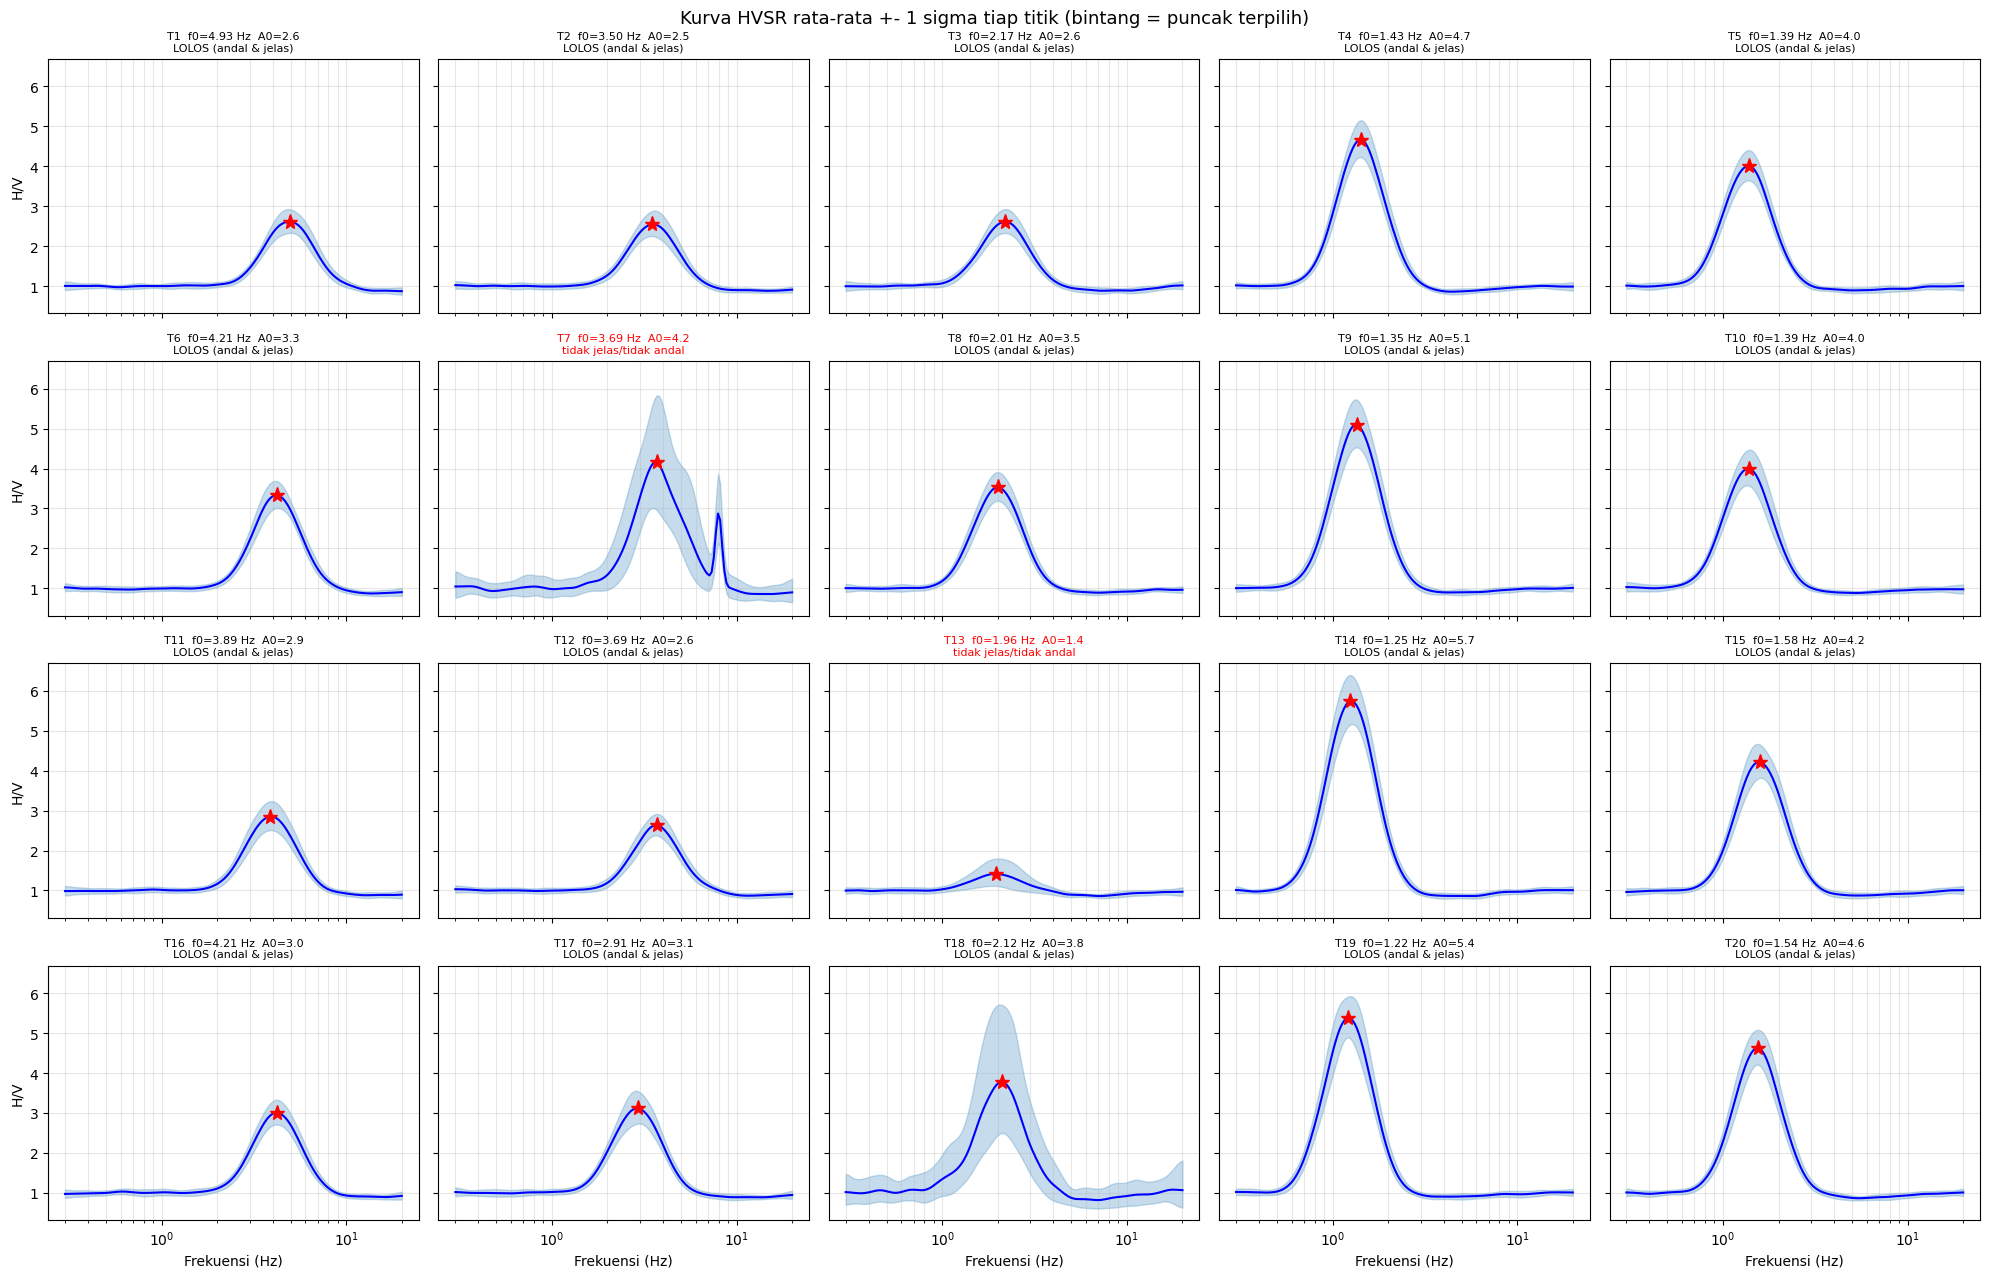

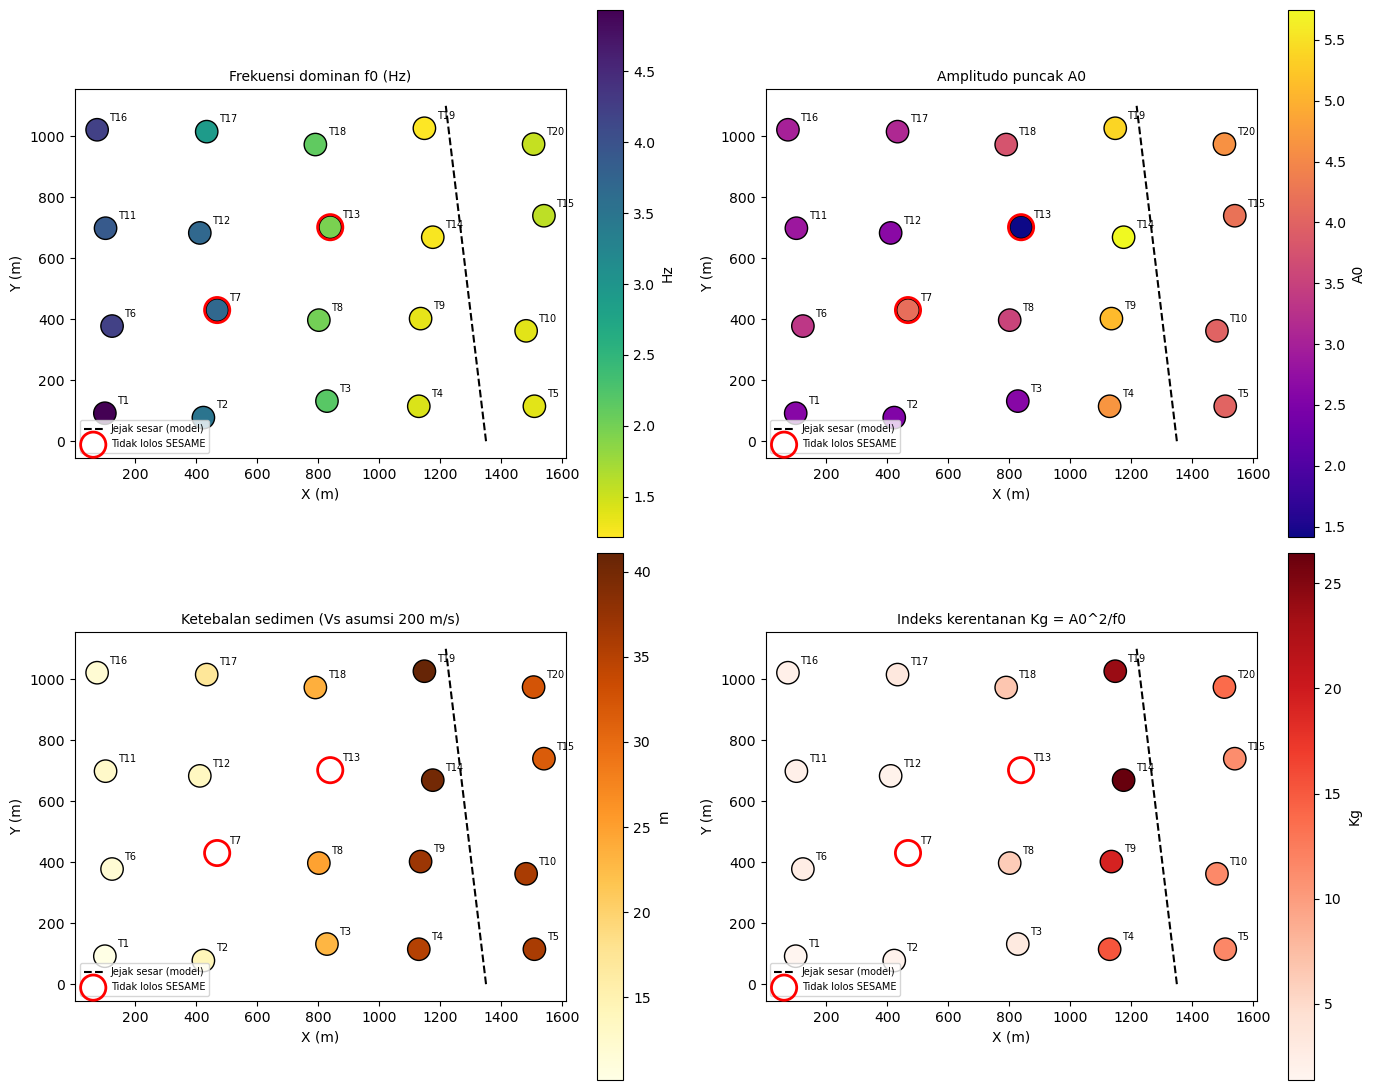

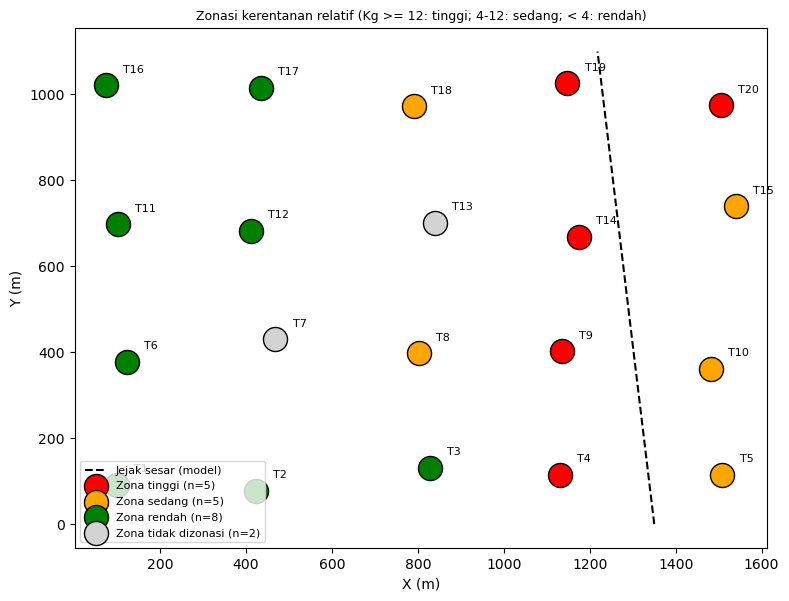

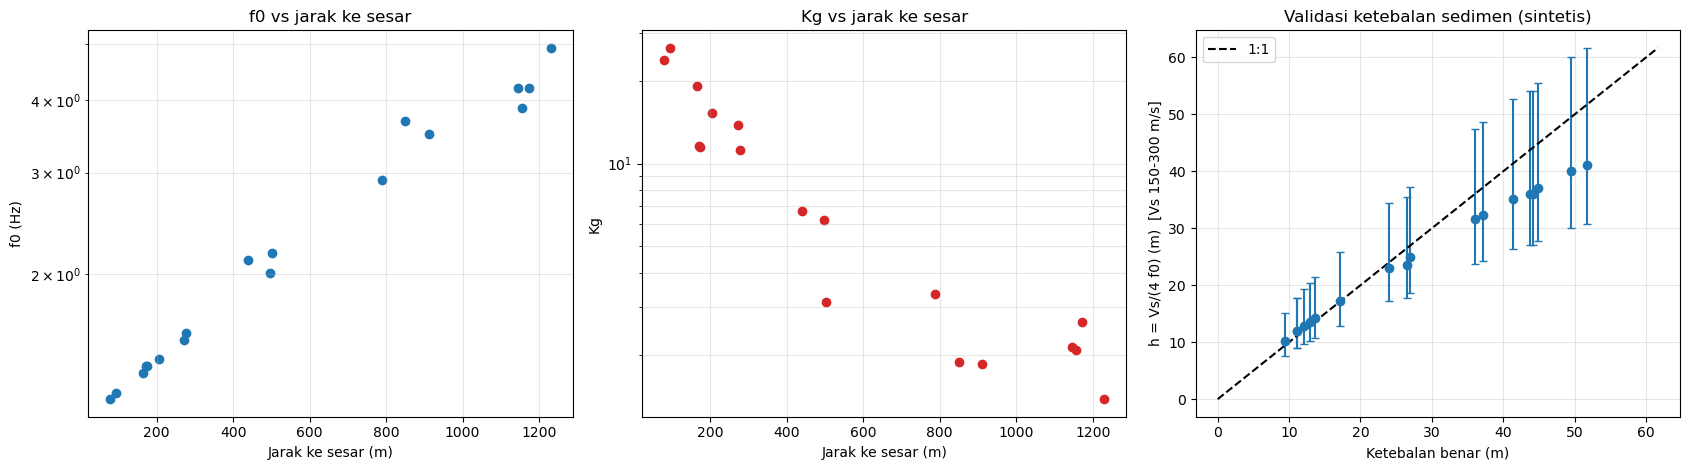

In [46]:
# ------------------------------------------------------------ gambar
fig, axs = plt.subplots(4, 5, figsize=(20, 13), sharex=True, sharey=True)
for i, ax in enumerate(axs.ravel()):
    L = np.log(curves[i]); m = np.exp(L.mean(0)); s = np.exp(L.std(0, ddof=1))
    ax.fill_between(freq, m / s, m * s, color="tab:blue", alpha=.25); ax.plot(freq, m, "b-")
    r = R.iloc[i]
    ax.plot(r.f0_Hz, r.A0, "r*", ms=11)
    ax.set_xscale("log"); ax.grid(alpha=.3, which="both")
    col = "k" if r.status.startswith("LOLOS") else "red"
    ax.set_title(f"T{i+1}  f0={r.f0_Hz:.2f} Hz  A0={r.A0:.1f}\n{r.status}", fontsize=8, color=col)
for a in axs[-1]: a.set_xlabel("Frekuensi (Hz)")
for a in axs[:, 0]: a.set_ylabel("H/V")
fig.suptitle("Kurva HVSR rata-rata +- 1 sigma tiap titik (bintang = puncak terpilih)", fontsize=13)
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "01_kurva_HVSR_20_titik.png"), dpi=120); plt.show()

yy = np.linspace(0, 1100, 40)
def basemap(ax, vals, title, cmap, label, vmin=None, vmax=None, annotate=True):
    ax.plot(fault_x(yy), yy, "k--", lw=1.5, label="Jejak sesar (model)")
    sc = ax.scatter(R.x_m, R.y_m, c=vals, s=260, cmap=cmap, edgecolor="k", vmin=vmin, vmax=vmax)
    bad = ~ok
    ax.scatter(R.x_m[bad], R.y_m[bad], s=330, facecolors="none", edgecolors="red", linewidths=2, label="Tidak lolos SESAME")
    if annotate:
        for _, r in R.iterrows(): ax.text(r.x_m + 40, r.y_m + 30, f"T{int(r.titik)}", fontsize=7)
    plt.colorbar(sc, ax=ax, label=label); ax.set_title(title, fontsize=10); ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)")
    ax.set_aspect("equal"); ax.legend(loc="lower left", fontsize=7)
fig, axs = plt.subplots(2, 2, figsize=(14, 11))
basemap(axs[0, 0], R.f0_Hz, "Frekuensi dominan f0 (Hz)", "viridis_r", "Hz")
basemap(axs[0, 1], R.A0, "Amplitudo puncak A0", "plasma", "A0")
basemap(axs[1, 0], R.h_Vs200_m, "Ketebalan sedimen (Vs asumsi 200 m/s)", "YlOrBr", "m")
basemap(axs[1, 1], R.Kg, "Indeks kerentanan Kg = A0^2/f0", "Reds", "Kg")
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "02_peta_f0_A0_h_Kg.png"), dpi=125); plt.show()

fig, ax = plt.subplots(figsize=(8, 7))
cmap = {"tinggi": "red", "sedang": "orange", "rendah": "green", "tidak dizonasi": "lightgrey"}
ax.plot(fault_x(yy), yy, "k--", lw=1.5, label="Jejak sesar (model)")
for z, c in cmap.items():
    s = R[R.zona == z]; ax.scatter(s.x_m, s.y_m, s=300, c=c, edgecolor="k", label=f"Zona {z} (n={len(s)})")
for _, r in R.iterrows(): ax.text(r.x_m + 40, r.y_m + 30, f"T{int(r.titik)}", fontsize=8)
ax.set_aspect("equal"); ax.legend(fontsize=8, loc="lower left"); ax.set_xlabel("X (m)"); ax.set_ylabel("Y (m)")
ax.set_title(f"Zonasi kerentanan relatif (Kg >= {KG_TINGGI:g}: tinggi; {KG_SEDANG:g}-{KG_TINGGI:g}: sedang; < {KG_SEDANG:g}: rendah)", fontsize=9)
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "03_zonasi_kerentanan.png"), dpi=130); plt.show()

fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
o = R[ok]
axs[0].scatter(o.jarak_sesar_m, o.f0_Hz, c="tab:blue"); axs[0].set_xlabel("Jarak ke sesar (m)"); axs[0].set_ylabel("f0 (Hz)"); axs[0].set_yscale("log")
axs[1].scatter(o.jarak_sesar_m, o.Kg, c="tab:red"); axs[1].set_xlabel("Jarak ke sesar (m)"); axs[1].set_ylabel("Kg"); axs[1].set_yscale("log")
axs[2].errorbar(o.h_benar_m, o.h_Vs200_m, yerr=[o.h_Vs200_m - o.h_min_m, o.h_maks_m - o.h_Vs200_m], fmt="o", capsize=3)
mx = max(o.h_maks_m.max(), o.h_benar_m.max()); axs[2].plot([0, mx], [0, mx], "k--", label="1:1")
axs[2].set_xlabel("Ketebalan benar (m)"); axs[2].set_ylabel("h = Vs/(4 f0) (m)  [Vs 150-300 m/s]"); axs[2].legend()
for a in axs: a.grid(alpha=.3, which="both")
axs[0].set_title("f0 vs jarak ke sesar"); axs[1].set_title("Kg vs jarak ke sesar"); axs[2].set_title("Validasi ketebalan sedimen (sintetis)")
fig.tight_layout(); fig.savefig(os.path.join(HASIL, "04_hubungan_dan_validasi.png"), dpi=130); plt.show()

In [47]:
# ------------------------------------------------------------ ringkasan
pd.set_option("display.width", 250)
print(R[["titik", "catatan", "f0_Hz", "A0", "sigma_f0_Hz", "sigmaA_f0", "n_kriteria_puncak", "kurva_andal", "status"]].round(2).to_string(index=False))
print("\nKriteria gagal pada titik tidak lolos:")
for _, r in R[~ok].iterrows():
    print(" T%d: " % r.titik + ", ".join(k for k in ["R1", "R2", "R3", "C1", "C2", "C3", "C4", "C5", "C6"] if not r[k]))
print("\nTabel ringkas (titik lolos):\n", R[ok][["titik", "f0_Hz", "A0", "h_Vs200_m", "h_min_m", "h_maks_m", "Kg", "zona", "jarak_sesar_m"]].round(2).to_string(index=False))
print("\nJumlah lolos: %d / 20 ; zona: %s" % (ok.sum(), R.zona.value_counts().to_dict()))
print("Korelasi log f0 vs jarak sesar: %.2f ; log Kg vs jarak: %.2f" % (np.corrcoef(np.log(o.f0_Hz), o.jarak_sesar_m)[0, 1], np.corrcoef(np.log(o.Kg), o.jarak_sesar_m)[0, 1]))
print("Rentang f0 %.2f-%.2f Hz, A0 %.1f-%.1f, Kg %.1f-%.1f, h(Vs200) %.1f-%.1f m" % (o.f0_Hz.min(), o.f0_Hz.max(), o.A0.min(), o.A0.max(), o.Kg.min(), o.Kg.max(), o.h_Vs200_m.min(), o.h_Vs200_m.max()))
print("Galat h(Vs=200) vs benar: rata2 %.1f m ; benar di dalam rentang 150-300: %d / %d" %
      ((o.h_Vs200_m - o.h_benar_m).abs().mean(), ((o.h_benar_m >= o.h_min_m) & (o.h_benar_m <= o.h_maks_m)).sum(), len(o)))

 titik                               catatan  f0_Hz   A0  sigma_f0_Hz  sigmaA_f0  n_kriteria_puncak  kurva_andal                  status
     1                         cerah, tenang   4.93 2.61         0.43       1.12                  5         True   LOLOS (andal & jelas)
     2                         cerah, tenang   3.50 2.55         0.23       1.13                  5         True   LOLOS (andal & jelas)
     3                         cerah, tenang   2.17 2.61         0.15       1.12                  5         True   LOLOS (andal & jelas)
     4                         cerah, tenang   1.43 4.67         0.06       1.10                  6         True   LOLOS (andal & jelas)
     5                         cerah, tenang   1.39 4.01         0.07       1.10                  6         True   LOLOS (andal & jelas)
     6                         cerah, tenang   4.21 3.33         0.25       1.11                  5         True   LOLOS (andal & jelas)
     7         lalu lintas padat dekat ti

## **Interpretasi**
**Kualitas data.** 18 dari 20 titik lolos kurva andal dan puncak jelas; 2 titik dikeluarkan. T7 menunjukkan puncak sempit pada ±8 Hz dengan simpangan antar jendela besar (σ f0 = 1,45 Hz): khas gangguan sumber monokromatik (lalu lintas/mesin), bukan resonansi tanah, sehingga f0 yang terbaca (3,69 Hz) tidak dipercaya. T13 hampir datar (A0 = 1,41): kontras impedansi sedimen–batuan dasar lemah, sehingga HVSR tidak dapat memberi f0 yang berarti; metode lain (MASW, ERT) diperlukan. **T18 lolos marginal** (5/6 kriteria): σ f0 = 0,44 Hz jauh di atas ambang 0,11 Hz dan σA(f0) = 1,51 hampir menyentuh batas 1,58, sehingga hasilnya (f0 2,12 Hz) kurang dapat diandalkan dan sebaiknya diukur ulang pada kondisi tenang.

**Sebaran f0 dan A0.** Titik lolos memiliki f0 **1,22–4,93 Hz** dan A0 **2,5–5,7**. f0 rendah (1,2–1,6 Hz; T4, T5, T9, T10, T14, T15, T19, T20) dengan A0 tinggi (4,0–5,7) menandai sedimen tebal dan kontras impedansi besar; f0 tinggi (≈ 3,5–4,9 Hz) dengan A0 rendah (2,5–3,3) menandai sedimen tipis.

**Ketebalan sedimen.** Dengan Vs 200 m/s: 10–41 m (T1 ≈ 10,1 m hingga T19 ≈ 41,1 m); dengan Vs 150–300 m/s rentang keseluruhan 7,6–61,7 m (mis. T19: 30,8–61,7 m). Rentang lebar ini adalah akibat **asumsi Vs**, bukan galat data; angka tunggal tidak boleh disajikan sebagai hasil pasti. Validasi sintetis: rentang 150–300 m/s memuat ketebalan benar pada 18 dari 18 titik (galat rata-rata h pada Vs 200 m/s ≈ 3,9 m).

**Kerentanan relatif dan pola spasial.** Kg 1,4–26,4. Zona **tinggi** (Kg ≥ 12): T4, T9, T14, T19, T20 — semuanya berjarak 78–271 m dari sesar; zona **sedang**: T5, T8, T10, T15, T18; zona **rendah** (Kg < 4): T1, T2, T3, T6, T11, T12, T16, T17 (jarak 502–1230 m). Hubungan jarak–sesar sangat jelas: log f0 berkorelasi 0,99 dengan jarak ke sesar dan log Kg berkorelasi −0,94: makin dekat sesar, makin tebal sedimen, makin rendah f0, makin tinggi Kg. Pola ini sesuai skenario geologi sintetis (sedimen menebal mendekati zona sesar di sisi timur) dan wajar secara fisik, karena blok yang turun menampung endapan lunak; pada data nyata hubungan sekuat ini tidak boleh diasumsikan, melainkan diuji.

**Makna dan batas.** Kg adalah **indikator relatif antar titik**, bukan prediksi kerusakan; ambang 4 dan 12 adalah asumsi dan akan bergeser bila ambang lain atau sebaran data lain dipakai. Tingkat kerusakan gempa tidak disimpulkan. Zona tinggi berarti "lebih rentan terhadap amplifikasi guncangan dibanding titik lain di kawasan ini", bukan nilai absolut.